# Данные

**Dataset:** LiveLib / "По страницам"

**Source:** https://ods.ai/competitions/nto25-26-hack/dataset.

Датасет содержит обезличенную историю взаимодействий пользователей с книгами и метаданные книг, изданий и пользователей.

### interactions.csv:
Лог событий взаимодействий пользователя с изданиями, каждая строка - одно событие.
- user_id - идентификатор пользователя (FK => users.user_id);
- edition_id - идентификатор издания (FK => editions.edition_id);
- event_type - тип события: 1 - wishlist, 2 - read;
- rating - рейтинг (только для read, иначе NULL);
- event_ts - дата-время события.

### users.csv:
Справочник пользователей с демографическими признаками.
- user_id - идентификатор пользователя (PK);
- gender - пол: 1 - мужской, 2 - женский, NULL - неизвестен;
- age - возраст (может быть NULL).

### editions.csv:
Справочник изданий, каждое издание привязано к одной книге.
- edition_id - идентификатор издания (PK);
- book_id - идентификатор книги;
- author_id - идентификатор автора (FK → authors.author_id);
- publication_year - год публикации	(издания, не книги);
- age_restriction - возрастное ограничение (например, 18+);
- language_id - идентификатор языка (справочник отсутствует);
- publisher_id - идентификатор издателя	(справочник отсутствует);
- title - название;
- description - описание (сравнительно короткое, нестандартизированное).

### authors.csv:
Справочник авторов.
- author_id - идентификатор автора (PK);
- author_name - имя автора (необязательно ФИО, может быть и псевдонимом, и даже несколькими авторами).

### genres.csv:
Справочник жанров.
- genre_id - идентификатор жанра (PK);
- genre_name - название жанра.

### book_genres.csv:
Связь многие-ко-многим между книгами и жанрами, уникальность: (book_id, genre_id).
- book_id - идентификатор книги;
- genre_id - идентификатор жанра (FK → genres.genre_id).

Исходный датасет содержит 231 210 взаимодействий, 5 067 пользователей, 134 231 изданий (74 528 со взаимодействиями) из которых 105 752 уникальных книг (59 026 со взаимодействиями).

Пользователю будем рекомендовать топ-10 наиболее релевантных, ранее не прочитанных книг. Релевантный объект - книга с будущим событием read в validation или test.

Для начала работы необходимо перенести в корень проекта папку models (при запуске в колабе), а так же создать в корне проекта папку data.

In [ ]:
import torch
import random
import zipfile
import numpy as np
import polars as pl
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt

In [ ]:
# для корректного отображения середин таблиц в колабе
pl.Config.set_tbl_rows(20)
pl.Config.set_tbl_cols(20)
pl.Config.set_tbl_width_chars(200)

polars.config.Config

In [ ]:
SEED = 42
K = 10

DATA_DIR = Path("data")
RAW_DIR = DATA_DIR / "raw"
ARCHIVE_PATH = DATA_DIR / "participants.zip"
SOURCE_DIR = RAW_DIR / "participants" / "data"

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

In [ ]:
!wget -O /content/data/participants.zip "https://storage.yandexcloud.net/ds-ods/files/files/4b118d73/participants.zip"

--2026-10-27 13:19:44--  https://storage.yandexcloud.net/ds-ods/files/files/4b118d73/participants.zip
Resolving storage.yandexcloud.net (storage.yandexcloud.net)... 213.180.193.243, 2a02:6b8::1d9
Connecting to storage.yandexcloud.net (storage.yandexcloud.net)|213.180.193.243|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 58566707 (56M) [application/zip]
Saving to: ‘/content/data/participants.zip’

/content/data/parti 100%[===================>]  55.85M  8.24MB/s    in 8.0s    

2026-10-27 13:19:54 (6.97 MB/s) - ‘/content/data/participants.zip’ saved [58566707/58566707]



In [ ]:
if not SOURCE_DIR.exists():
    if not ARCHIVE_PATH.exists():
        raise FileNotFoundError
    RAW_DIR.mkdir(parents=True, exist_ok=True)
    with zipfile.ZipFile(ARCHIVE_PATH, "r") as archive:
        archive.extractall(RAW_DIR)
sorted(p.name for p in SOURCE_DIR.glob("*.csv"))

['authors.csv',
 'book_genres.csv',
 'editions.csv',
 'genres.csv',
 'interactions.csv',
 'users.csv']

In [ ]:
interactions = pl.read_csv(
    SOURCE_DIR / "interactions.csv",
    schema_overrides={"event_ts": pl.Datetime},
)
users = pl.read_csv(SOURCE_DIR / "users.csv")
editions = pl.read_csv(SOURCE_DIR / "editions.csv")
authors = pl.read_csv(SOURCE_DIR / "authors.csv")
genres = pl.read_csv(SOURCE_DIR / "genres.csv")
book_genres = pl.read_csv(SOURCE_DIR / "book_genres.csv")

# EDA

In [ ]:
# таблицы в целом
tables = {
    "interactions": interactions,
    "users": users,
    "editions": editions,
    "authors": authors,
    "genres": genres,
    "book_genres": book_genres,
}
for name, df in tables.items():
    print(f"\n{name}: {df.shape}")
    display(df.head())


interactions: (231210, 5)


user_id,edition_id,event_type,rating,event_ts
i64,i64,i64,f64,datetime[μs]
560,1012411658,2,6.0,2024-12-24 19:02:14
560,1008465904,2,6.0,2025-01-10 19:18:04
560,1001243738,2,10.0,2025-01-25 11:28:11
560,1009492501,2,8.0,2025-01-25 11:28:42
560,1000118974,2,8.0,2025-03-10 18:14:17



users: (5067, 3)


user_id,gender,age
i64,f64,f64
560,2.0,9.0
3410,2.0,39.0
5620,1.0,42.0
5700,2.0,40.0
6120,2.0,32.0



editions: (134231, 9)


...

author_id,author_name
i64,str
1,"""Грегори Бенфорд"""
6,"""Вячеслав Маркин"""
18,"""Эдвард де Боно"""
19,"""Василий Головачёв"""
21,"""Пауло Коэльо"""



genres: (586, 2)


genre_id,genre_name
i64,str
1,"""Бизнес-книги"""
2,"""Банковское-дело"""
3,"""Бухучет-налогообложение-аудит"""
4,"""Государственное-и-муниципально…"
5,"""Делопроизводство"""



book_genres: (168251, 2)


book_id,genre_id
i64,i64
20,433
20,1217
35,141
35,142
35,146


In [ ]:
# nunique, в случае изданий - считаем только те, которые встретились в interactions
used_editions = interactions.select("edition_id").unique()
used_books = editions.join(used_editions, on="edition_id", how="semi")
stats = pl.DataFrame({
    "col": ["interactions", "users", "editions", "books"],
    "value": [
        interactions.height,
        interactions["user_id"].n_unique(),
        interactions["edition_id"].n_unique(),
        used_books["book_id"].n_unique(),
    ]
})
stats

col,value
str,i64
"""interactions""",231210
"""users""",5067
"""editions""",74528
"""books""",59026


In [ ]:
# общие статистики
interactions.describe()

statistic,user_id,edition_id,event_type,rating,event_ts
str,f64,f64,f64,f64,str
"""count""",231210.0,231210.0,231210.0,125369.0,"""231210"""
"""null_count""",0.0,0.0,0.0,105841.0,"""0"""
"""mean""",5.4696e6,1.0070e9,1.634311,8.286474,"""2025-01-15 22:08:00.221378"""
"""std""",4.0050e6,3.7931e6,0.481624,1.779718,null
"""min""",560.0,1.0000e9,1.0,1.0,"""2024-10-14 18:48:56"""
"""25%""",1.36127e6,1.0030e9,1.0,8.0,"""2024-12-04 22:11:41"""
"""50%""",5.51959e6,1.0079e9,2.0,8.0,"""2025-01-16 14:51:51"""
"""75%""",9.08446e6,1.0100e9,2.0,10.0,"""2025-02-27 16:29:33"""
"""max""",1.195162e7,1.0159e9,2.0,10.0,"""2025-04-12 12:44:23"""


Рейтинг - по десятибалльной шкале, у 105841 взаимодействий отсутствует, смещен вверх (mean = 8.286474).

Пропусков в таймстемпах нет, период оценивания: 14.10.2024 - 12.04.2025.

rating,count
f64,u32
null,105841
1.0,234
2.0,1247
3.0,388
4.0,3454
5.0,1933
6.0,14823
7.0,9233
8.0,35921


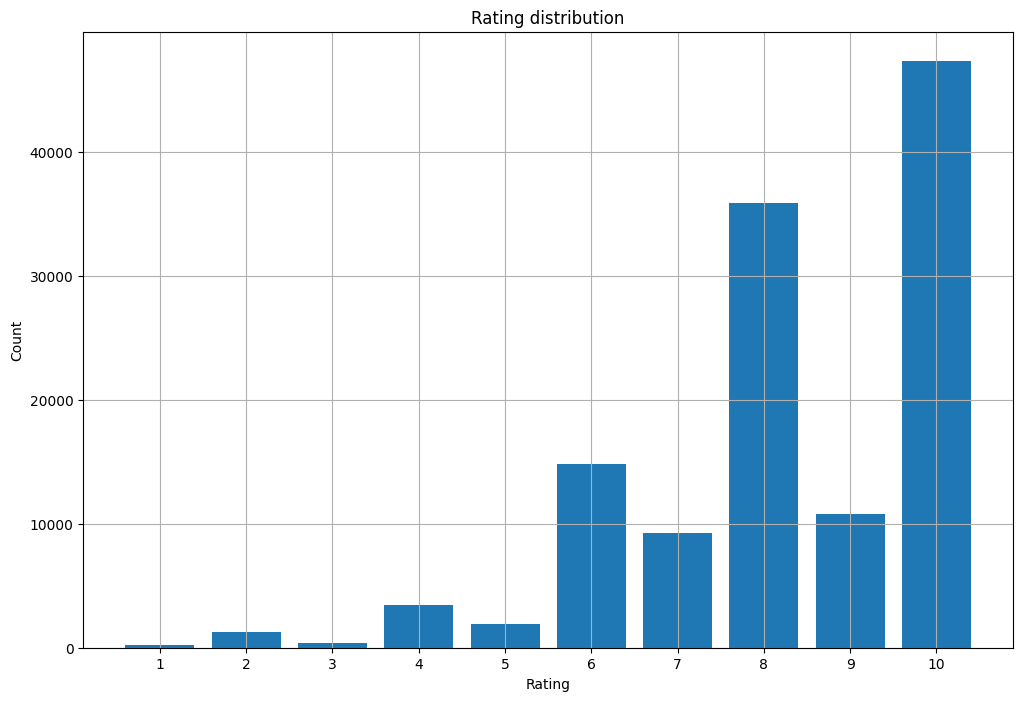

In [ ]:
# распределение рейтингов
rating_counts = (
    interactions
    .group_by("rating")
    .len(name="count")
    .sort("rating", nulls_last=False)
)
display(rating_counts)

rated_counts = rating_counts.filter(pl.col("rating").is_not_null())
plt.figure(figsize=(12, 8))
plt.bar(
    rated_counts["rating"].to_numpy(),
    rated_counts["count"].to_numpy(),
)
plt.title("Rating distribution")
plt.xlabel("Rating")
plt.ylabel("Count")
plt.xticks(rated_counts["rating"].to_numpy())
plt.grid(True)
plt.show()

Помимо смещенности вверх: среднее - 8.29, самые частые оценки - 8 и 10 (возможные причины - человек скорее оценит издание, которое ему понравилось, нежели наоборот + человек скорее прочитает более популярное ~= понравившееся многим издание), интересно, что нечетные рейтинги проигрывают четным.

In [ ]:
# статистика по типам взаимодействий:
# 1 - пользователь добавил издание в список желаемого, 2 - пользователь прочитал издание
event_type_stats = (
    interactions
    .group_by("event_type")
    .len(name="count")
    .with_columns((pl.col("count") / pl.col("count").sum()).alias("share"))
    .sort("event_type")
)
event_type_stats

event_type,count,share
i64,u32,f64
1,84551,0.365689
2,146659,0.634311


In [ ]:
# покрытие рейтингов по типам событий
rating_by_event = (
    interactions
    .group_by("event_type")
    .agg(
        pl.len().alias("events"),
        pl.col("rating").is_not_null().sum().alias("rated_events"),
        pl.col("rating").is_null().sum().alias("unrated_events"),
        pl.col("rating").is_not_null().mean().alias("rating_coverage"),
    )
    .sort("event_type")
)
rated = interactions.filter(
    pl.col("rating").is_not_null()
    & pl.col("event_ts").is_not_null()
)
rated_coverage = pl.DataFrame({
    "metric": [
        "rated_interactions",
        "rated_users",
        "rated_editions",
        "rated_interactions_share",
        "rated_users_share",
        "rated_editions_share",
    ],
    "value": [
        rated.height,
        rated["user_id"].n_unique(),
        rated["edition_id"].n_unique(),
        rated.height / interactions.height,
        rated["user_id"].n_unique() / interactions["user_id"].n_unique(),
        rated["edition_id"].n_unique() / interactions["edition_id"].n_unique(),
    ],
}, strict=False)
display(rating_by_event)
display(rated_coverage)

event_type,events,rated_events,unrated_events,rating_coverage
i64,u32,u32,u32,f64
1,84551,0,84551,0.0
2,146659,125369,21290,0.854833


metric,value
str,f64
"""rated_interactions""",125369.0
"""rated_users""",4785.0
"""rated_editions""",48995.0
"""rated_interactions_share""",0.54223
"""rated_users_share""",0.944346
"""rated_editions_share""",0.657404


month,count
datetime[μs],u32
2024-10-01 00:00:00,19460
2024-11-01 00:00:00,33896
2024-12-01 00:00:00,36521
2025-01-01 00:00:00,48207
2025-02-01 00:00:00,37414
2025-03-01 00:00:00,40758
2025-04-01 00:00:00,14954


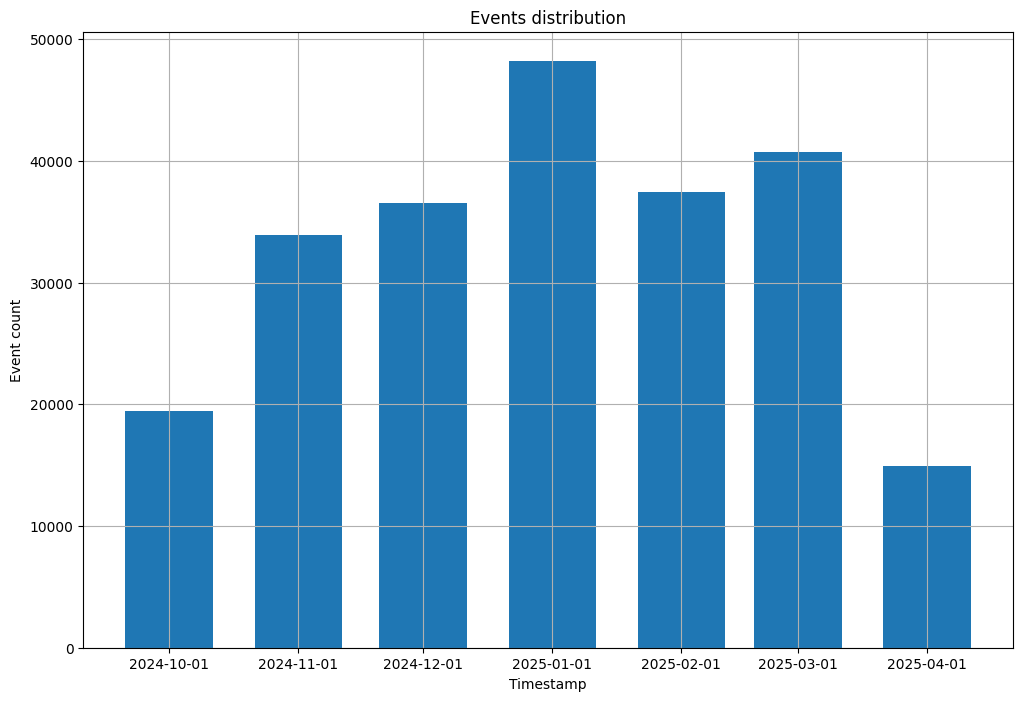

In [ ]:
# распределение событий по месяцам
events_counts = (
    interactions
    .with_columns(pl.col("event_ts").dt.truncate("1mo").alias("month"))
    .group_by("month")
    .len(name="count")
    .sort("month", nulls_last=False)
)
display(events_counts)

events_counts = events_counts.filter(pl.col("month").is_not_null())
plt.figure(figsize=(12, 8))
plt.bar(
    events_counts["month"].to_numpy(),
    events_counts["count"].to_numpy(),
    width=pd.Timedelta(weeks=3),
)
plt.title("Events distribution")
plt.xlabel("Timestamp")
plt.ylabel("Event count")
plt.xticks(events_counts["month"].to_numpy())
plt.grid(True)
plt.show()

Возможно, пик в январе можно объяснить новогодними праздниками.

In [ ]:
# полные дубликаты взаимодействий
duplicates_count = (
    interactions
    .select(pl.struct(pl.all()).is_duplicated().sum())
    .item()
)
# дубликаты взаимодействий пользователь-издание
ui_duplicates_counts = (
    interactions
    .group_by(["user_id", "edition_id"])
    .len(name="n_events")
)
repeated = ui_duplicates_counts.filter(pl.col("n_events") > 1)
duplicates_stats = pl.DataFrame({
    "metric": [
        "duplicates",
        "unique_ui",
        "repeated_ui",
        "users_with_repeated_items",
        "extra_events",
        "max_events_for_ui",
    ],
    "value": [
        duplicates_count,
        ui_duplicates_counts.height,
        repeated.height,
        repeated["user_id"].n_unique(),
        interactions.height - ui_duplicates_counts.height,
        repeated["n_events"].max(),
    ],
})
duplicates_stats

metric,value
str,i64
"""duplicates""",0
"""unique_ui""",231038
"""repeated_ui""",163
"""users_with_repeated_items""",110
"""extra_events""",172
"""max_events_for_ui""",3


Полных дубликатов нет, а повторных пар пользователь-издание мало, но просто их удалять нельзя, т.к. список желаемого -> прочтение одного и того же издания - осмысленная последовательность.

In [ ]:
# вся история пар пользователь-издание, у которых есть события обоих типов
repeated_events = (
    interactions
    .filter(
        (pl.col("event_type").is_in([1]).any() & pl.col("event_type").is_in([2]).any())
        .over(["user_id", "edition_id"])
    )
    .sort(["user_id", "edition_id", "event_type", "event_ts"])
)
repeated_events.head(100)

user_id,edition_id,event_type,rating,event_ts
i64,i64,i64,f64,datetime[μs]
216910,1002828837,1,null,2025-03-07 11:43:06
216910,1002828837,2,9.0,2025-03-07 11:43:06
1141490,1006889170,1,null,2025-03-25 15:27:07
1141490,1006889170,2,10.0,2025-03-25 15:27:26
1831770,1008891292,1,null,2024-11-22 12:22:14
1831770,1008891292,2,6.0,2025-03-22 11:24:34
2675700,1010163694,1,null,2024-12-09 17:36:31
2675700,1010163694,2,8.0,2024-12-09 17:33:39
2703960,1009712347,1,null,2025-01-08 00:05:21


Хотя, судя по event_ts, некоторые события (например, user_id=216910, edition_id=1002828837) произошли в один момент времени, хотя занесение в список желаемого одновременно с прочтением смысла не имеет.

In [ ]:
user_activity = (
    interactions
    .group_by("user_id")
    .len(name="n_interactions")
)
user_activity.select("n_interactions").describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

statistic,n_interactions
str,f64
"""count""",5067.0
"""null_count""",0.0
"""mean""",45.630551
"""std""",46.268933
"""min""",5.0
"""50%""",30.0
"""75%""",57.0
"""90%""",102.0
"""95%""",143.0


В датасете уже как минимум 5 взаимодействий на пользователя, и хорошая активность с медианой в 30 взаимодействий, и максимумом в 290, что дает хорошее подспорье для выбора user2user в качестве коллаборативного подхода, особенно учитывая небольшое число пользователей (относительно числа изданий: 5067 vs 74 528).

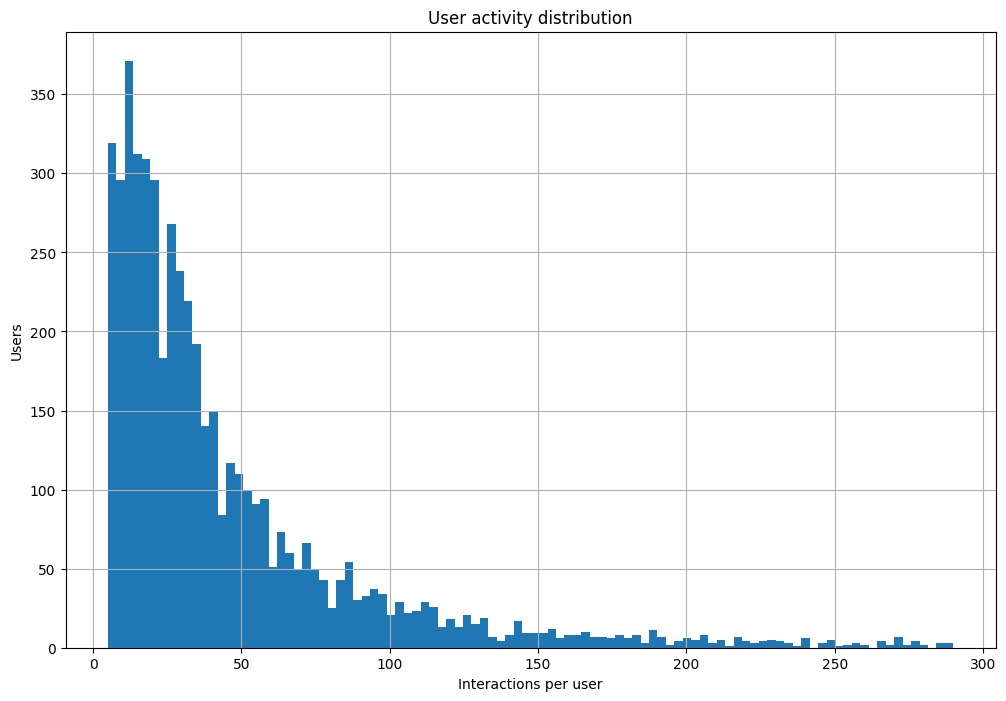

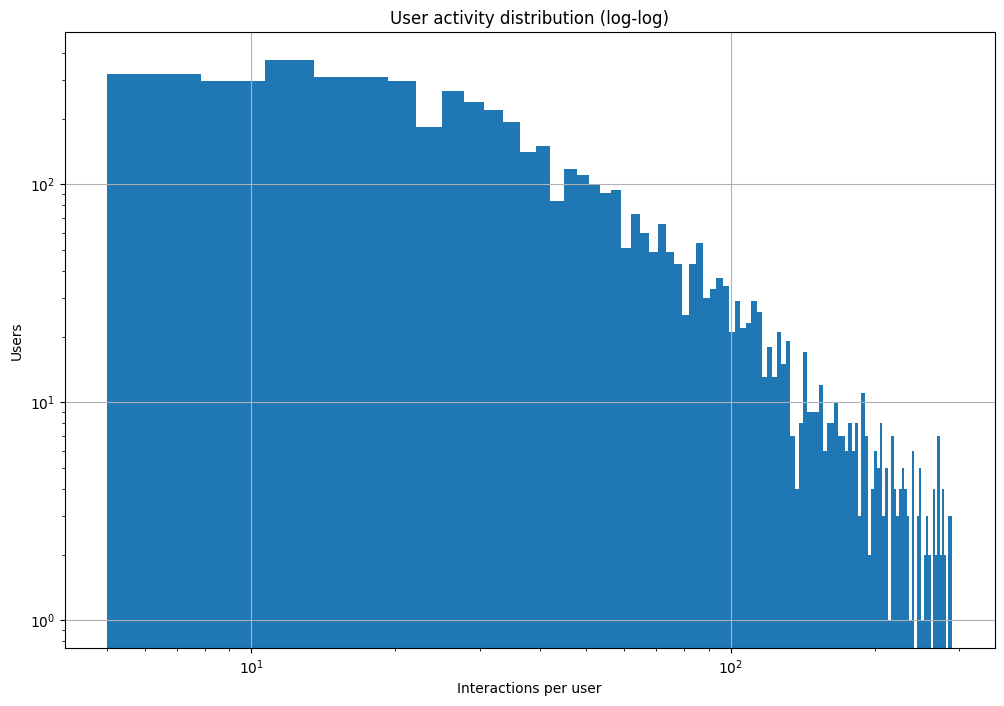

In [ ]:
values = user_activity["n_interactions"].to_numpy()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.title("User activity distribution")
plt.xlabel("Interactions per user")
plt.ylabel("Users")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.xscale("log")
plt.yscale("log")
plt.title("User activity distribution (log-log)")
plt.xlabel("Interactions per user")
plt.ylabel("Users")
plt.grid(True)
plt.show()

In [ ]:
item_popularity = (
    interactions
    .group_by("edition_id")
    .len(name="n_interactions")
)
item_popularity.select("n_interactions").describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

statistic,n_interactions
str,f64
"""count""",74528.0
"""null_count""",0.0
"""mean""",3.102324
"""std""",8.203192
"""min""",1.0
"""50%""",1.0
"""75%""",2.0
"""90%""",6.0
"""95%""",11.0


С изданиями все не так гладко, медиана взаимодействий - 1, в среднем - 3.10, 90-ый перцентиль - 6, поэтому item2item подход выглядит менее хорошим вариантом, так как сходства между изданиями могут быть не так надежны.

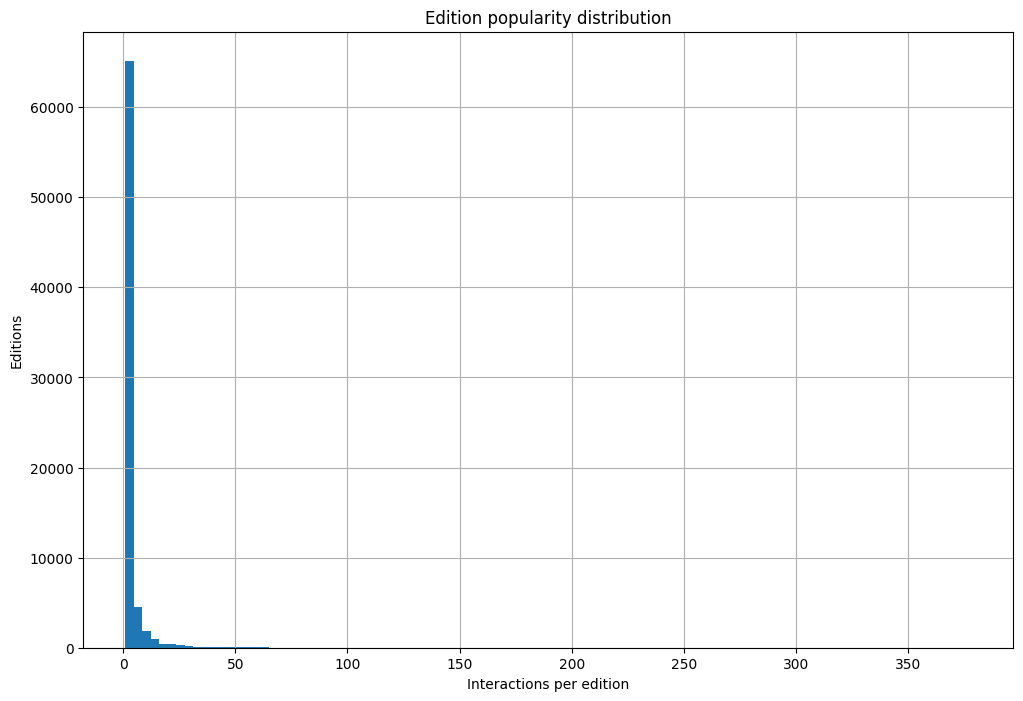

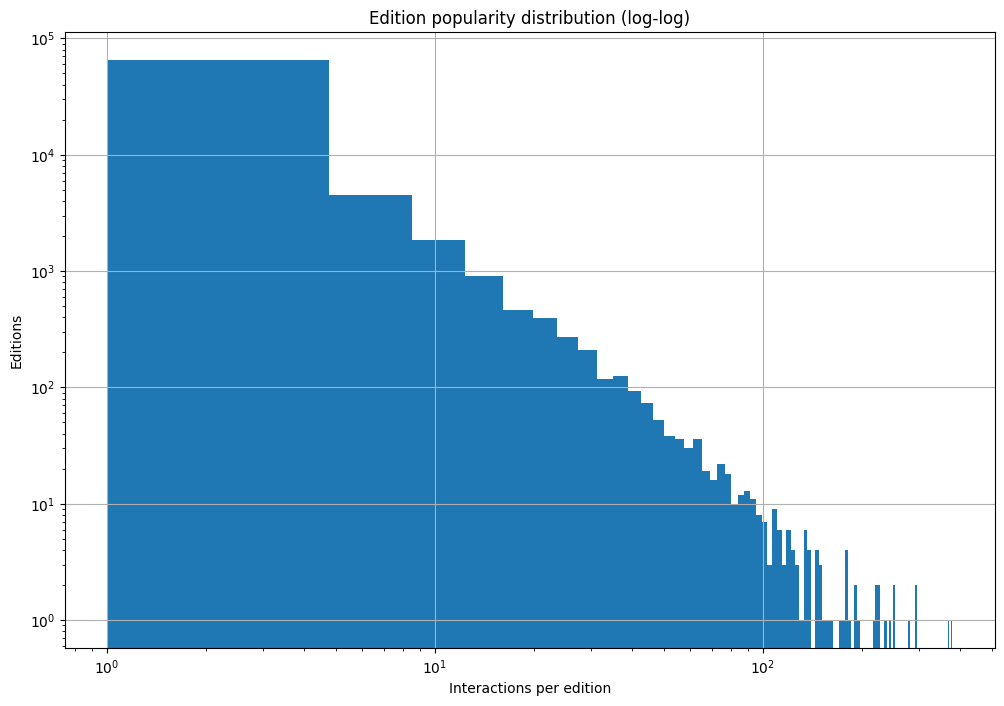

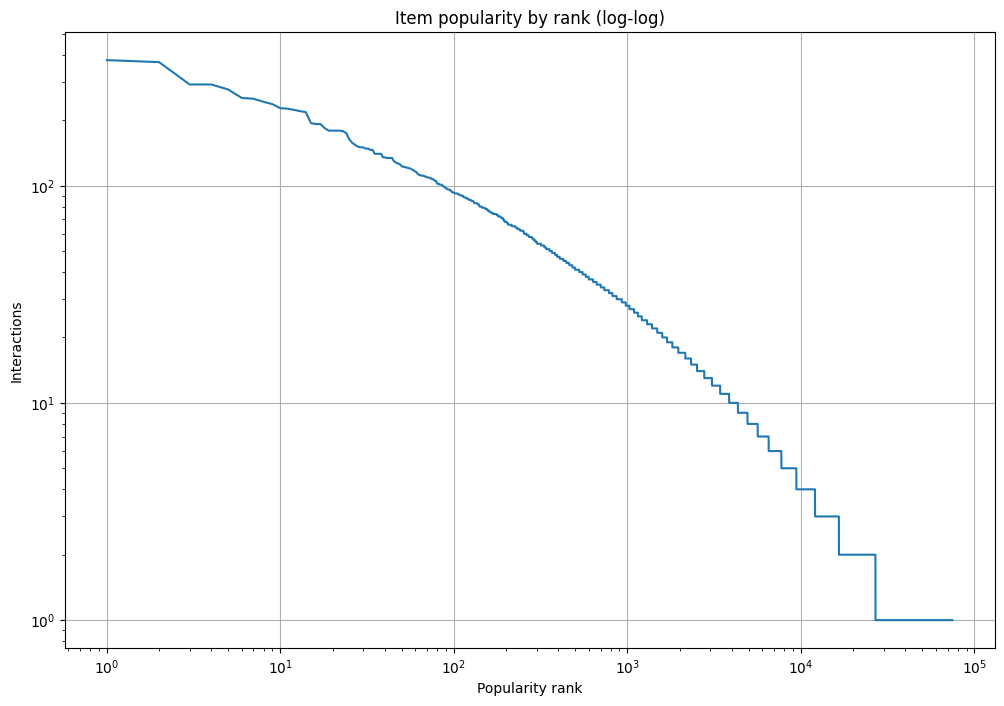

In [ ]:
values = item_popularity["n_interactions"].to_numpy()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.title("Edition popularity distribution")
plt.xlabel("Interactions per edition")
plt.ylabel("Editions")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.xscale("log")
plt.yscale("log")
plt.title("Edition popularity distribution (log-log)")
plt.xlabel("Interactions per edition")
plt.ylabel("Editions")
plt.grid(True)
plt.show()

popularity = (
    item_popularity
    .sort("n_interactions", descending=True)["n_interactions"]
    .to_numpy()
)
plt.figure(figsize=(12, 8))
plt.plot(
    np.arange(1, len(popularity) + 1),
    popularity,
)
plt.xscale("log")
plt.yscale("log")
plt.title("Item popularity by rank (log-log)")
plt.xlabel("Popularity rank")
plt.ylabel("Interactions")
plt.grid(True)
plt.show()

In [ ]:
# доля взаимодействий у самых популярных изданий
popularity_sorted = item_popularity.sort("n_interactions", descending=True)
total_interactions = popularity_sorted["n_interactions"].sum()
for share in [0.01, 0.05, 0.10]:
    n = max(1, int(popularity_sorted.height * share))
    interaction_share = (
        popularity_sorted["n_interactions"].head(n).sum()
        / total_interactions
    )
    print(f"Top {share:.0%} editions: {interaction_share:.2%} of all interactions")

Top 1% editions: 20.38% of all interactions
Top 5% editions: 43.19% of all interactions
Top 10% editions: 55.72% of all interactions


In [ ]:
# плотность и разреженность коллаборативной матрицы
n_users = interactions["user_id"].n_unique()
n_items = interactions["edition_id"].n_unique()
n_unique_pairs = (
    interactions
    .select(
        pl.struct(["user_id", "edition_id"])
        .n_unique()
        .alias("n_unique_pairs")
    )
    .item()
)

density = n_unique_pairs / (n_users * n_items)
sparsity = 1.0 - density
pl.DataFrame({
    "metric": ["users", "items", "unique_pairs", "density", "sparsity"],
    "value": [n_users, n_items, n_unique_pairs, density, sparsity],
}, strict=False)

metric,value
str,f64
"""users""",5067.0
"""items""",74528.0
"""unique_pairs""",231038.0
"""density""",0.000612
"""sparsity""",0.999388


Матрица взаимодействий разреженная + есть явно выраженный длинный хвост распределения популярных изданий => есть резон брать most_popular как бейзлайн.

In [ ]:
# добавления в список желаемого и прочтения на пользователей
event_activity = (
    interactions
    .group_by(["user_id", "event_type"])
    .len(name="n_events")
    .pivot(
        on="event_type",
        index="user_id",
        values="n_events",
        aggregate_function="first",
    )
    .fill_null(0)
    .rename({
        "1": "wishlist",
        "2": "read",
    })
)
event_activity.select(["wishlist", "read"]).describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

statistic,wishlist,read
str,f64,f64
"""count""",5067.0,5067.0
"""null_count""",0.0,0.0
"""mean""",16.6866,28.943951
"""std""",31.174801,29.297345
"""min""",0.0,0.0
"""50%""",4.0,21.0
"""75%""",18.0,35.0
"""90%""",50.0,60.0
"""95%""",77.0,84.0


Необходимо не менее трех релевантных объектов на пользователя (1 или более для трейна, 1 для валидации, 1 для теста - temporal leave-two-out)

In [ ]:
user_ratings = (
    interactions
    .filter((pl.col("event_type") == 2) & pl.col("rating").is_not_null())
    .group_by("user_id")
    .len(name="n_ratings")
)

feedback_stats = (
    event_activity
    .join(user_ratings, on="user_id", how="left")
    .with_columns(pl.col("n_ratings").fill_null(0))
    .select(
        pl.len().alias("users"),
        (pl.col("wishlist") == 0).sum().alias("without_wishlist"),
        (pl.col("wishlist") < 3).sum().alias("lt_3_wishlist"),
        (pl.col("wishlist") >= 3).sum().alias("geq_3_wishlist"),
        (pl.col("read") == 0).sum().alias("without_read"),
        (pl.col("read") < 3).sum().alias("lt_3_reads"),
        (pl.col("read") >= 3).sum().alias("geq_3_reads"),
        (pl.col("n_ratings") == 0).sum().alias("without_ratings"),
        (pl.col("n_ratings") < 3).sum().alias("lt_3_ratings"),
        (pl.col("n_ratings") >= 3).sum().alias("geq_3_ratings"),
    )
)
display(feedback_stats)

users,without_wishlist,lt_3_wishlist,geq_3_wishlist,without_read,lt_3_reads,geq_3_reads,without_ratings,lt_3_ratings,geq_3_ratings
u32,u32,u32,u32,u32,u32,u32,u32,u32,u32
5067,1549,2205,2862,47,118,4949,282,515,4552


В качестве общего сигнала релевантности будем использовать "read", т.к. он покрывает больше пользователей и не отбрасывает прочтения без оценки, а рейтинги пойдут для обучения timeSVD++.

In [ ]:
# статистика по метаданным
def metadata_stats(df: pl.DataFrame, columns: list[str]) -> pl.DataFrame:
    return pl.DataFrame({
        "feature": columns,
        "missing": [df[col].null_count() for col in columns],
        "missing_share": [df[col].null_count() / df.height for col in columns],
        "n_unique": [df[col].n_unique() for col in columns],
    }).sort("missing_share", descending=True)

edition_features = [
    "book_id", "author_id", "publication_year", "age_restriction",
    "language_id", "publisher_id", "title", "description",
]
user_features = ["gender", "age"]
display(metadata_stats(editions, edition_features))
display(metadata_stats(users, user_features))

feature,missing,missing_share,n_unique
str,i64,f64,i64
"""description""",8055,0.060008,122952
"""book_id""",0,0.0,105752
"""author_id""",0,0.0,36360
"""publication_year""",0,0.0,137
"""age_restriction""",0,0.0,19
"""language_id""",0,0.0,46
"""publisher_id""",0,0.0,6318
"""title""",0,0.0,105758


feature,missing,missing_share,n_unique
str,i64,f64,i64
"""gender""",171,0.033748,3
"""age""",90,0.017762,75


Также есть вариант рекомендовать пользователям не издание (edition_id), а книгу (перейти к book_id) - это семантически естественнее, т.к., например, использование edition_id может привести к дублированиям по сути одной книги в топе рекомендаций, однако часть событий при таком переходе может схлопнуться.

In [ ]:
editions_per_book = (
    editions
    .group_by("book_id")
    .agg(pl.col("edition_id").n_unique().alias("n_editions"))
)
editions_stats = pl.DataFrame({
    "metric": [
        "books",
        "gt_1_edition",
        "geq_5_editions",
        "max_editions",
    ],
    "value": [
        editions_per_book.height,
        editions_per_book.filter(pl.col("n_editions") > 1).height,
        editions_per_book.filter(pl.col("n_editions") >= 5).height,
        editions_per_book["n_editions"].max(),
    ],
})
display(editions_per_book.select("n_editions").describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
))
display(editions_stats)

book_conflicts = []
for feature in ["author_id", "publication_year", "language_id", "publisher_id"]:
    values_per_book = (
        editions
        .group_by("book_id")
        .agg(pl.col(feature).drop_nulls().n_unique().alias("n_values"))
    )
    book_conflicts.append({
        "multiple_features": feature,
        "book_counts": values_per_book.filter(
            pl.col("n_values") > 1
        ).height,
    })
display(pl.DataFrame(book_conflicts))

statistic,n_editions
str,f64
"""count""",105752.0
"""null_count""",0.0
"""mean""",1.2693
"""std""",1.255983
"""min""",1.0
"""50%""",1.0
"""75%""",1.0
"""90%""",2.0
"""95%""",2.0


metric,value
str,i64
"""books""",105752
"""gt_1_edition""",14355
"""geq_5_editions""",1478
"""max_editions""",65


multiple_features,book_counts
str,i64
"""author_id""",369
"""publication_year""",12748
"""language_id""",2776
"""publisher_id""",10032


In [ ]:
interactions_editions_books = interactions.join(
    editions.select(["edition_id", "book_id"]),
    on="edition_id",
    how="left",
)
read_interactions_editions_books = interactions_editions_books.filter(pl.col("event_type") == 2)

def item_comparison(df: pl.DataFrame, event_type: str, item: str) -> dict:
    n_users = df["user_id"].n_unique()
    n_items = df[item].n_unique()
    n_pairs = df.select(
        pl.struct(["user_id", item]).n_unique().alias("n_pairs")
    ).item()
    return {
        "event_type": event_type,
        "item": item,
        "events": df.height,
        "users": n_users,
        "items": n_items,
        "unique_ui_count": n_pairs,
        "collapsed_events": df.height - n_pairs,
        "density": n_pairs / (n_users * n_items),
        "sparsity": 1 - n_pairs / (n_users * n_items),
        "i2i_f64_gb": n_items**2 * 8 / 1024**3,
    }
edition_vs_book = pl.DataFrame([
    item_comparison(interactions_editions_books, "all", "edition_id"),
    item_comparison(interactions_editions_books, "all", "book_id"),
    item_comparison(read_interactions_editions_books, "read", "edition_id"),
    item_comparison(read_interactions_editions_books, "read", "book_id"),
])
edition_vs_book

event_type,item,events,users,items,unique_ui_count,collapsed_events,density,sparsity,i2i_f64_gb
str,str,i64,i64,i64,i64,i64,f64,f64,f64
"""all""","""edition_id""",231210,5067,74528,231038,172,0.000612,0.999388,41.383675
"""all""","""book_id""",231210,5067,59026,230904,306,0.000772,0.999228,25.958334
"""read""","""edition_id""",146659,5020,55644,146506,153,0.000524,0.999476,23.068895
"""read""","""book_id""",146659,5020,44324,146429,230,0.000658,0.999342,14.637537


Видно, что переход к book_id пойдет на пользу, так как мы не потеряем много полезных взаимодействий (число уникальных пар user-item сокращается только на 77 пар, около 0.05%), при этом не будем получать издания одной книги в топе рекомендаций, а так же сократится общее число объектов с 55 644 до 44 324, что важно для обучения, например, EASE, где используется матрица i2i, память под которую растет квадратично от числа объектов.

Поля publication_year, language_id и publisher_id могут различаться между изданиями одной книги, поэтому в FM будем использовать: book-признаки - авторы и жанры; user-признаки - age (по бакетам) и gender. Все выбранные признаки являются статическими данными пользователя или книги и доступны до момента формирования рекомендации.

In [ ]:
# далее используем item_id
interactions = interactions_editions_books.with_columns(
    pl.col("book_id").alias("item_id")
)
display(
    interactions.select(
        pl.len().alias("events"),
        pl.col("user_id").n_unique().alias("users"),
        pl.col("item_id").n_unique().alias("books"),
    )
)
# оставляем только уникальные read-события
read_interactions = (
    interactions
    .filter(pl.col("event_type") == 2)
    .sort(["user_id", "event_ts", "item_id"])
    .unique(
        subset=["user_id", "item_id"],
        keep="first",
        maintain_order=True,
    )
)
read_interactions.select(
    pl.len().alias("events"),
    pl.col("user_id").n_unique().alias("users"),
    pl.col("item_id").n_unique().alias("books"),
)

events,users,books
u32,u32,u32
231210,5067,59026


events,users,books
u32,u32,u32
146429,5020,44324


Имеет смысл посмотреть на распределения книг, чтобы понять, сохраняются ли предположения об объектах из изданий.

In [ ]:
book_user_activity = (
    read_interactions
    .group_by("user_id")
    .len(name="n_interactions")
)
book_user_activity.select("n_interactions").describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

statistic,n_interactions
str,f64
"""count""",5020.0
"""null_count""",0.0
"""mean""",29.169124
"""std""",29.240044
"""min""",1.0
"""50%""",21.0
"""75%""",35.0
"""90%""",60.0
"""95%""",84.0


Появились пользователи с 1 взаимодействием, поэтому нужна будет фильтрация до как минимум 3, а так же несколько просела медиана до 21 взаимодействия (это преимущественно связано с переходом к только read-событиям), однако идея u2u подхода все еще выглядит неплохо.

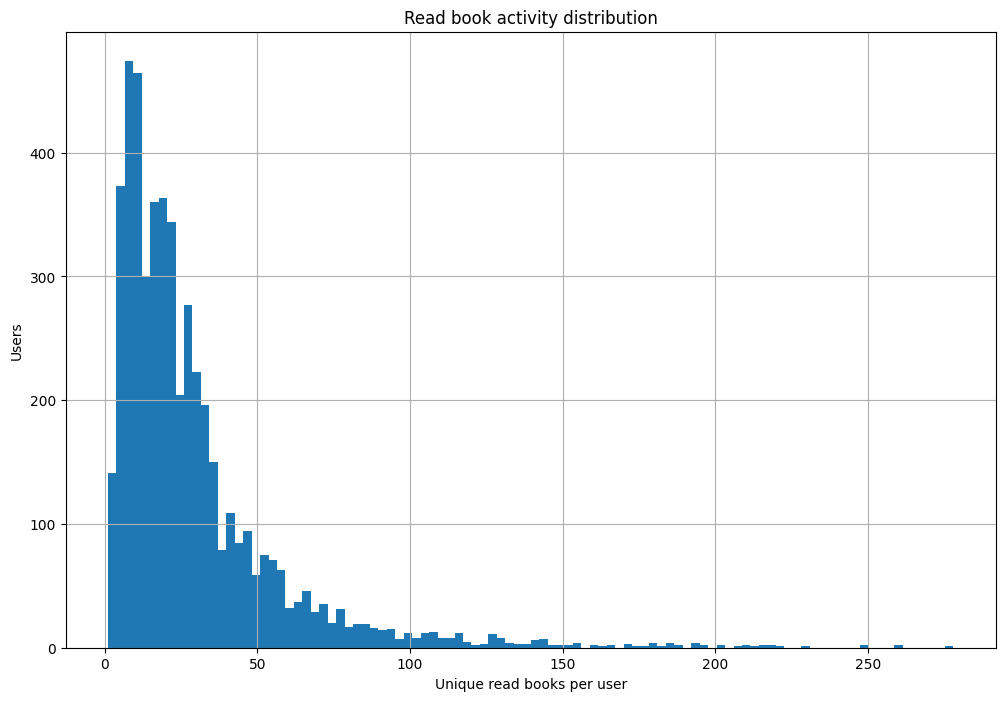

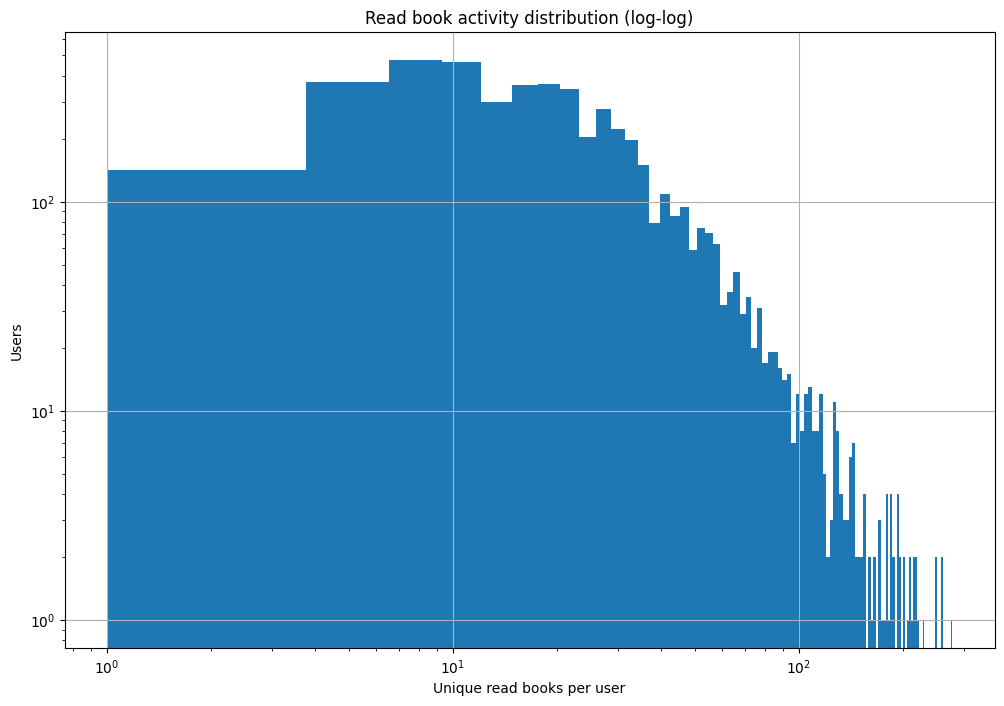

In [ ]:
values = book_user_activity["n_interactions"].to_numpy()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.title("Read book activity distribution")
plt.xlabel("Unique read books per user")
plt.ylabel("Users")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.xscale("log")
plt.yscale("log")
plt.title("Read book activity distribution (log-log)")
plt.xlabel("Unique read books per user")
plt.ylabel("Users")
plt.grid(True)
plt.show()

In [ ]:
book_popularity = (
    read_interactions
    .group_by("item_id")
    .len(name="n_readers")
)
book_popularity.select("n_readers").describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
)

statistic,n_readers
str,f64
"""count""",44324.0
"""null_count""",0.0
"""mean""",3.303605
"""std""",8.948752
"""min""",1.0
"""50%""",1.0
"""75%""",2.0
"""90%""",6.0
"""95%""",11.0


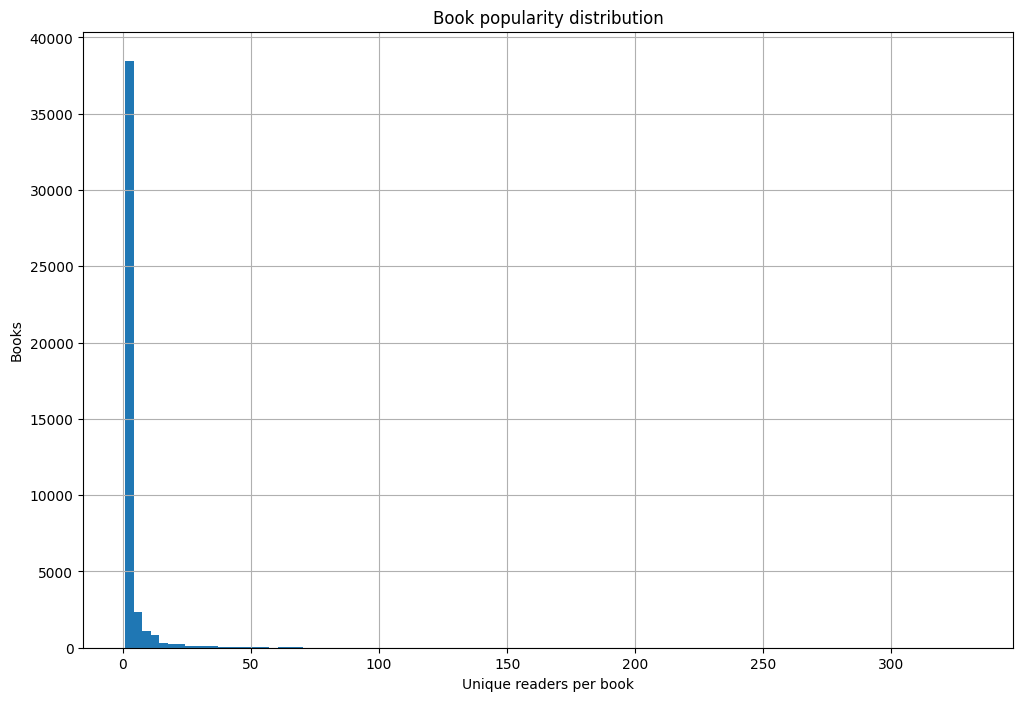

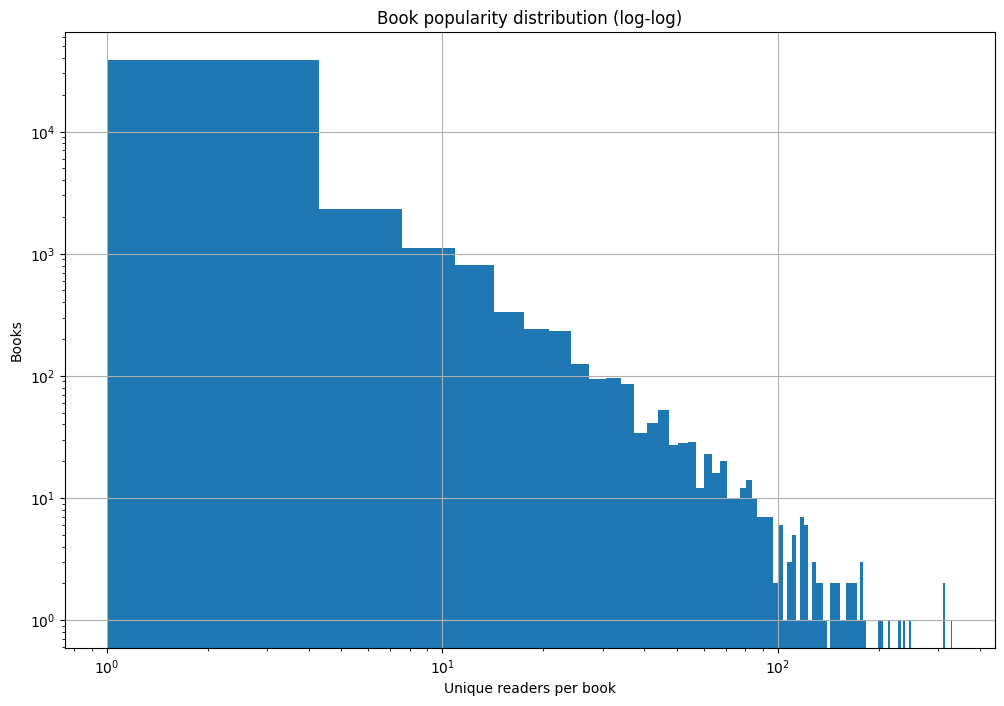

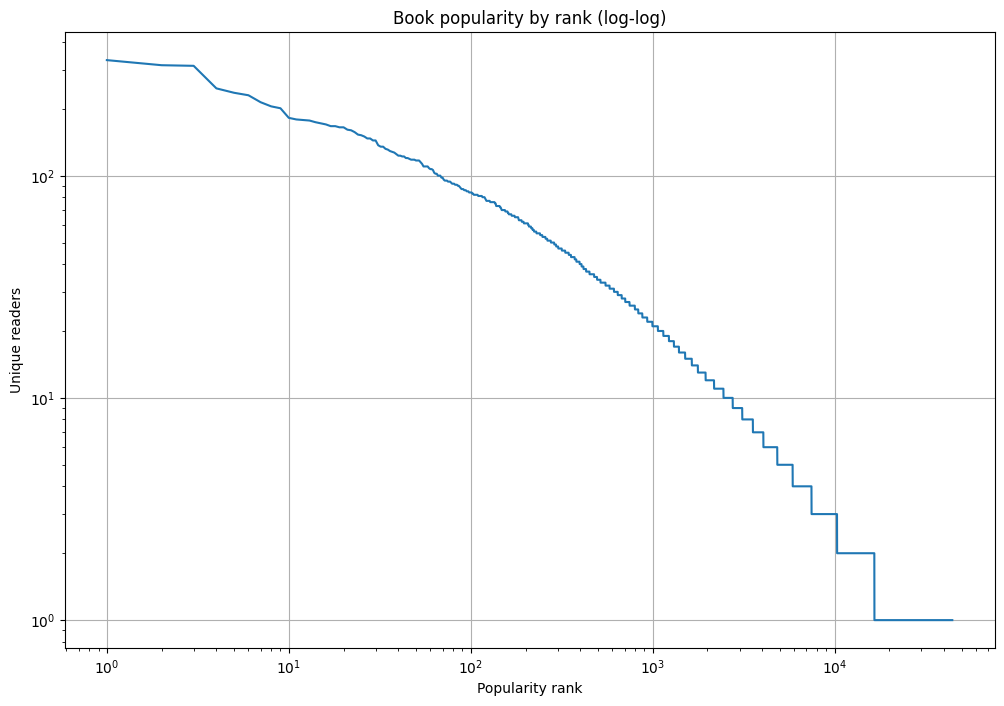

In [ ]:
values = book_popularity["n_readers"].to_numpy()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.title("Book popularity distribution")
plt.xlabel("Unique readers per book")
plt.ylabel("Books")
plt.grid(True)
plt.show()

plt.figure(figsize=(12, 8))
plt.hist(values, bins=100)
plt.xscale("log")
plt.yscale("log")
plt.title("Book popularity distribution (log-log)")
plt.xlabel("Unique readers per book")
plt.ylabel("Books")
plt.grid(True)
plt.show()

popularity = (
    book_popularity
    .sort("n_readers", descending=True)["n_readers"]
    .to_numpy()
)
plt.figure(figsize=(12, 8))
plt.plot(
    np.arange(1, len(popularity) + 1),
    popularity,
)
plt.xscale("log")
plt.yscale("log")
plt.title("Book popularity by rank (log-log)")
plt.xlabel("Popularity rank")
plt.ylabel("Unique readers")
plt.grid(True)
plt.show()

In [ ]:
popularity_sorted = book_popularity.sort("n_readers", descending=True)
total_read_interactions = popularity_sorted["n_readers"].sum()
for share in [0.01, 0.05, 0.10]:
    n = max(1, int(popularity_sorted.height * share))
    interaction_share = (
        popularity_sorted["n_readers"].head(n).sum()
        / total_read_interactions
    )
    print(f"Top {share:.0%} books: {interaction_share:.2%} of unique read interactions")

Top 1% books: 21.54% of unique read interactions
Top 5% books: 44.79% of unique read interactions
Top 10% books: 57.16% of unique read interactions


In [ ]:
n_users = read_interactions["user_id"].n_unique()
n_items = read_interactions["item_id"].n_unique()
n_unique_pairs = read_interactions.height

density = n_unique_pairs / (n_users * n_items)
sparsity = 1.0 - density
pl.DataFrame({
    "metric": ["users", "items", "unique_pairs", "density", "sparsity"],
    "value": [n_users, n_items, n_unique_pairs, density, sparsity],
}, strict=False)

metric,value
str,f64
"""users""",5020.0
"""items""",44324.0
"""unique_pairs""",146429.0
"""density""",0.000658
"""sparsity""",0.999342


С книгами ситуация по популярности по большей части сохраняется. Переход к book_id уменьшает каталог, но 44 324 книги - все еще много для прямого обучения EASE без последующей фильтрации.

In [ ]:
# еще раз посмотрим на метаданные
modeled_books = (
    read_interactions
    .select(pl.col("item_id").alias("book_id"))
    .unique()
)

book_author_features = (
    editions
    .join(modeled_books, on="book_id", how="semi")
    .group_by("book_id")
    .agg(
        pl.col("author_id").unique().sort().alias("author_ids"),
        pl.col("author_id").n_unique().alias("n_authors"),
    )
)
book_genre_features = (
    modeled_books
    .join(book_genres, on="book_id", how="left")
    .group_by("book_id")
    .agg(
        pl.col("genre_id").drop_nulls().unique().sort().alias("genre_ids"),
        pl.col("genre_id").drop_nulls().n_unique().alias("n_genres"),
    )
)
book_features = (
    modeled_books
    .join(book_author_features, on="book_id", how="left")
    .join(book_genre_features, on="book_id", how="left")
)

users_with_features = users.with_columns(
    pl.when(pl.col("gender").is_null()).then(pl.lit("unknown"))
    .when(pl.col("gender") == 1).then(pl.lit("male"))
    .when(pl.col("gender") == 2).then(pl.lit("female"))
    .otherwise(pl.lit("unknown"))
    .alias("gender_feature"),
    pl.when(pl.col("age").is_null()).then(pl.lit("unknown"))
    .when(pl.col("age") < 18).then(pl.lit("<18"))
    .when(pl.col("age") < 25).then(pl.lit("18-24"))
    .when(pl.col("age") < 35).then(pl.lit("25-34"))
    .when(pl.col("age") < 45).then(pl.lit("35-44"))
    .when(pl.col("age") < 55).then(pl.lit("45-54"))
    .otherwise(pl.lit("55+"))
    .alias("age_bucket"),
)

display(book_features.select(["n_authors", "n_genres"]).describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
))
display(users.select("age").describe(
    percentiles=[0.5, 0.75, 0.9, 0.95, 0.99]
))
display(users_with_features.group_by("gender_feature").len().sort("gender_feature"))
display(users_with_features.group_by("age_bucket").len().sort("age_bucket"))

statistic,n_authors,n_genres
str,f64,f64
"""count""",44324.0,44324.0
"""null_count""",0.0,0.0
"""mean""",1.006723,1.687641
"""std""",0.084168,0.852902
"""min""",1.0,1.0
"""50%""",1.0,1.0
"""75%""",1.0,2.0
"""90%""",1.0,3.0
"""95%""",1.0,3.0


statistic,age
str,f64
"""count""",4977.0
"""null_count""",90.0
"""mean""",31.552341
"""std""",9.23508
"""min""",5.0
"""50%""",31.0
"""75%""",36.0
"""90%""",42.0
"""95%""",46.0


gender_feature,len
str,u32
"""female""",4311
"""male""",585
"""unknown""",171


age_bucket,len
str,u32
"""18-24""",888
"""25-34""",2252
"""35-44""",1329
"""45-54""",261
"""55+""",88
"""<18""",159
"""unknown""",90


Почти каждая книга связана с одним автором: медиана и 99-й перцентиль равны 1, максимальное число авторов - 3. Жанров на книгу больше: медиана равна 1, среднее - 1.69, 90-й перцентиль - 3, максимум -8, поэтому авторов и жанры можно использовать как multi-hot признаки для FM наряду с категориальными user_id и book_id (авторы книги - объединение уникальных author_id всех ее изданий).

Пропусков в пользовательских признаках немного: возраст отсутствует у 90 пользователей, пол - у 171, для них используем категорию unknown. Распределение пола сильно несбалансировано в сторону женщин, что необходимо учитывать при интерпретации влияния этого признака. Возраст находится в диапазоне от 5 до 100 лет и содержит потенциальные крайние значения, поэтому для FM удобно использовать категориальный age_bucket.

Как уже упоминалось, для temporal leave-two-out необходимо оставить только тех пользователей, у которых как минимум 3 взаимодействия. Также можно сделать и подвыборку объектов, чтобы улучшить вычислимость i2i моделей. Удаляем итеративно до сходимости, т.к. после удаления, например, пользователя, у какого-то объекта может остаться <3 взаимодействия.

In [ ]:
MIN_INTERACTIONS = 3
PRIMARY_METRIC = f"NDCG@{K}"
SECONDARY_METRIC = f"Recall@{K}"

In [ ]:
filtered_interactions = read_interactions
history = []
iter = 0
while True:
    iter += 1
    prev_height = filtered_interactions.height

    active_users = (
        filtered_interactions
        .group_by("user_id")
        .len(name="support")
        .filter(pl.col("support") >= MIN_INTERACTIONS)
        .select("user_id")
    )
    filtered_interactions = filtered_interactions.join(
        active_users,
        on="user_id",
        how="semi",
    )

    active_items = (
        filtered_interactions
        .group_by("item_id")
        .len(name="support")
        .filter(pl.col("support") >= MIN_INTERACTIONS)
        .select("item_id")
    )
    filtered_interactions = filtered_interactions.join(
        active_items,
        on="item_id",
        how="semi",
    )

    history.append({
        "iteration": iter,
        "interactions": filtered_interactions.height,
        "users": filtered_interactions["user_id"].n_unique(),
        "items": filtered_interactions["item_id"].n_unique(),
    })

    if filtered_interactions.height == prev_height:
        break

filtered_interactions = filtered_interactions.sort(
    ["user_id", "event_ts", "item_id"]
)
history = pl.DataFrame(history)
display(history)
filtered_user_support = filtered_interactions.group_by("user_id").len(name="support")
filtered_item_support = filtered_interactions.group_by("item_id").len(name="support")
filtered_stats = pl.DataFrame({
    "interactions": [filtered_interactions.height],
    "users": [filtered_interactions["user_id"].n_unique()],
    "items": [filtered_interactions["item_id"].n_unique()],
    "min_user_support": [filtered_user_support["support"].min()],
    "min_item_support": [filtered_item_support["support"].min()],
    "i2i_float64_gib": [
        filtered_interactions["item_id"].n_unique() ** 2 * 8 / 1024 ** 3
    ],
})
filtered_stats

iteration,interactions,users,items
i64,i64,i64,i64
1,106086,4928,10295
2,105849,4817,10265
3,105845,4816,10264
4,105845,4816,10264


interactions,users,items,min_user_support,min_item_support,i2i_float64_gib
i64,i64,i64,i64,i64,f64
105845,4816,10264,3,3,0.784916


Оставляем 105 845 взаимодействий, 4 816 пользователей и 10 264 книги - достаточно взаимодействий с хорошим саппортом, при этом за счет уменьшения числа объектов в разы упал размер матрицы i2i.

In [ ]:
# собственно temporal leave-two-out
ordered_interactions = filtered_interactions.sort(
    ["user_id", "event_ts", "item_id"]
)
test = (
    ordered_interactions
    .group_by("user_id", maintain_order=True)
    .tail(1)
)
interactions_before_test = ordered_interactions.join(
    test.select(["user_id", "item_id"]),
    on=["user_id", "item_id"],
    how="anti",
)
validation = (
    interactions_before_test
    .group_by("user_id", maintain_order=True)
    .tail(1)
)
train = interactions_before_test.join(
    validation.select(["user_id", "item_id"]),
    on=["user_id", "item_id"],
    how="anti",
)

# при одинаковом таймстемпе дополнительно сортируем по item_id
train = train.sort(["user_id", "event_ts", "item_id"])
validation = validation.sort("user_id")
test = test.sort("user_id")

split_stats = pl.DataFrame({
    "split": ["train", "validation", "test"],
    "interactions": [train.height, validation.height, test.height],
    "users": [
        train["user_id"].n_unique(),
        validation["user_id"].n_unique(),
        test["user_id"].n_unique(),
    ],
    "items": [
        train["item_id"].n_unique(),
        validation["item_id"].n_unique(),
        test["item_id"].n_unique(),
    ],
})
display(split_stats)

split,interactions,users,items
str,i64,i64,i64
"""train""",96213,4816,10254
"""validation""",4816,4816,3038
"""test""",4816,4816,3054


Дополнительно на валидации нужно оставить пользователей, чей целевой объект есть в трейне. После фиксации всех параметров и обучении модели на тренировочной + валидационной выборках (refit) отдельно сделаем выборку пользователей, чей тест-объект есть в рефит-выборке. Также у каждого пользователя из соответствующей выборки исключаются уже известные ему книги.

In [ ]:
train_items = train.select("item_id").unique()
validation_warm = validation.join(
    train_items,
    on="item_id",
    how="semi",
)
validation_eval = validation_warm.sort("user_id")
total_users = validation["user_id"].n_unique()
warm_start_stats = (
    pl.DataFrame({
        "metric": [
            "validation_users",
            "warm_validation_users",
        ],
        "users": [
            total_users,
            validation_eval["user_id"].n_unique(),
        ],
    })
    .with_columns(
        (pl.col("users") / total_users).alias("share")
    )
)
display(warm_start_stats)

metric,users,share
str,i64,f64
"""validation_users""",4816,1.0
"""warm_validation_users""",4798,0.996262


In [ ]:
import importlib
import models.utils
importlib.reload(models.utils)

<module 'models.utils' from '/content/models/utils.py'>

In [ ]:
(
    train_matrix,
    train_user_ids,
    train_item_ids,
    train_user_to_index,
    train_item_to_index,
) = models.utils.interactions_to_csr(train)
pl.DataFrame({
    "shape": [str(train_matrix.shape)],
    "nnz": [train_matrix.nnz],
    "train_users": [len(train_user_ids)],
    "eval_users": [validation_eval.height],
    "items": [len(train_item_ids)],
})

shape,nnz,train_users,eval_users,items
str,i64,i64,i64,i64
"""(4816, 10254)""",96213,4816,4798,10254


В качестве основной метрики будем использовать NDCG@10, как наиболее полная для нашей задачи метрика, т.к. она учтет не только попадание релевантной книги в топ-10, но и ее позицию. В качестве дополнительной метрики используем Recall@10 (в нашей задаче он по сути совпадает с HitRate@10, так как в валидационной и тестовой выборках пользователей находится по одной релевантной книге). Скоры моделей могут иметь разный масштаб, поэтому будем смотреть именно на порядковые метрики ранжирования.

Доступные моделям сигналы:
| Сигнал | Popularity | CF | iALS | EASE | FM | timeSVD++ |
|--|--|--|--|--|--|--|
| `read` | + | + | + | + | + | + |
| `rating` | - | - | - | - | - | + |
| `author`, `genre` | - | - | - | - | + | - |
| `gender`, `age` | - | - | - | - | + | - |
| `event_ts` | - | - | - | - | - | + |
*event_ts - именно в качестве признака

Гиперпараметры моделей выбираем на validation, потом обучим заново на train + validation, и один раз сравним на test.

In [ ]:
import time
from models.utils import Popularity, evaluate, run_grid_search
from models.cf import CF
from models.ials import IALS
from models.ease import EASE

RESULT_COLS = [
    "model", "parameters", "fit_sec", "eval_sec",
    "users", PRIMARY_METRIC, SECONDARY_METRIC,
]

## Popularity (baseline)
Одинаковый для всех пользователей рейтинг книг по числу трейн-прочтений:
$$
s_i = \sum_u R_{ui},
$$
где $R_{ui}=1$, если пользователь $u$ взаимодействовал с книгой $i$, и $0$ иначе, затем для каждого пользователя книги ранжируются по $s_i$ в порядке убывания.

In [ ]:
started = time.perf_counter()
popularity_model = Popularity().fit(train_matrix)
fit_seconds = time.perf_counter() - started

started = time.perf_counter()
popularity_metrics, popularity_details = evaluate(
    popularity_model, validation_eval, train_matrix,
    train_user_to_index, train_item_to_index, k=K,
)
eval_seconds = time.perf_counter() - started

validation_rows = [{
    "model": "Popularity",
    "parameters": "-",
    "fit_sec": round(fit_seconds, 3),
    "eval_sec": round(eval_seconds, 3),
    **popularity_metrics.row(0, named=True),
}]
pl.DataFrame(validation_rows).select(RESULT_COLS)

model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""Popularity""","""-""",0.001,0.989,4798,0.011615,0.023343


## User2user CF

Пусть $R$ - бинарная коллаборативная матрица, для пользователей $u$ и $v$ сначала определяется число общих прочитанных книг:
$$
n_{uv} = |I_u \cap I_v|.
$$
Косинусная схожесть со shrinkage:
$$
\operatorname{sim}(u,v)
=
\frac{n_{uv}}
{\sqrt{|I_u|\,|I_v|}}
\cdot
\frac{n_{uv}}
{n_{uv}+\lambda_s},
$$
где $\lambda_s$ - параметр shrinkage.

Если $n_{uv} < \text{min_common}$, сходство полагается равным нулю. После этого для каждого пользователя сохраняются только $K$ наиболее похожих соседей.

Скор книги $i$ для пользователя $u$ вычисляется как
$$
s_{ui}
=
\sum_{v \in N_K(u)}
\operatorname{sim}(u,v) R_{vi}.
$$
Книги, уже прочитанные пользователем, исключаются перед формированием топ-10.

Проведем по размеру окрестности, силе shrinkage и минимальному числу общих книг, данные разреженны, поэтому значения min_common небольшие.

In [ ]:
CF_CONFIGS = [
    {
        "n_neighbors": n_neighbors,
        "shrinkage": shrinkage,
        "min_common": min_common,
    }
    for n_neighbors in [20, 50, 100, 200]
    for shrinkage in [0.0, 5.0, 10.0, 25.0, 50.0]
    for min_common in [1, 2]
]
validation_rows = [row for row in validation_rows if row["model"] != "CF"]
(
    cf_rows,
    best_cf_model,
    best_cf_parameters,
    best_cf_details,
) = run_grid_search(CF, "CF", CF_CONFIGS, (train_matrix,), validation_eval,
                    train_matrix, train_user_to_index, train_item_to_index, k=K)
validation_rows.extend(cf_rows)
best_cf_score = max(row[PRIMARY_METRIC] for row in cf_rows)
cf_validation = (
    pl.DataFrame(cf_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(cf_validation.head(10))
print(f"Лучшие параметры CF: {best_cf_parameters}")

CF 1/40: {'n_neighbors': 20, 'shrinkage': 0.0, 'min_common': 1}
  NDCG@10=0.0626, Recall@10=0.0909
CF 2/40: {'n_neighbors': 20, 'shrinkage': 0.0, 'min_common': 2}
  NDCG@10=0.0596, Recall@10=0.0863
CF 3/40: {'n_neighbors': 20, 'shrinkage': 5.0, 'min_common': 1}
  NDCG@10=0.0633, Recall@10=0.0930
CF 4/40: {'n_neighbors': 20, 'shrinkage': 5.0, 'min_common': 2}
  NDCG@10=0.0583, Recall@10=0.0850
CF 5/40: {'n_neighbors': 20, 'shrinkage': 10.0, 'min_common': 1}
  NDCG@10=0.0622, Recall@10=0.0905
CF 6/40: {'n_neighbors': 20, 'shrinkage': 10.0, 'min_common': 2}
  NDCG@10=0.0578, Recall@10=0.0842
CF 7/40: {'n_neighbors': 20, 'shrinkage': 25.0, 'min_common': 1}
  NDCG@10=0.0619, Recall@10=0.0913
CF 8/40: {'n_neighbors': 20, 'shrinkage': 25.0, 'min_common': 2}
  NDCG@10=0.0570, Recall@10=0.0844
CF 9/40: {'n_neighbors': 20, 'shrinkage': 50.0, 'min_common': 1}
  NDCG@10=0.0613, Recall@10=0.0911
CF 10/40: {'n_neighbors': 20, 'shrinkage': 50.0, 'min_common': 2}
  NDCG@10=0.0563, Recall@10=0.0838
CF 

model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""CF""","""{'n_neighbors': 50, 'shrinkage…",1.27,3.034,4798,0.070261,0.101084
"""CF""","""{'n_neighbors': 50, 'shrinkage…",1.266,2.984,4798,0.069336,0.103376
"""CF""","""{'n_neighbors': 100, 'shrinkag…",1.244,2.89,4798,0.069213,0.100667
"""CF""","""{'n_neighbors': 50, 'shrinkage…",1.265,2.958,4798,0.069189,0.099416
"""CF""","""{'n_neighbors': 100, 'shrinkag…",1.301,2.946,4798,0.069097,0.100875
"""CF""","""{'n_neighbors': 100, 'shrinkag…",1.223,2.875,4798,0.06899,0.100459
"""CF""","""{'n_neighbors': 100, 'shrinkag…",1.217,2.968,4798,0.068787,0.100459
"""CF""","""{'n_neighbors': 50, 'shrinkage…",1.333,3.014,4798,0.068272,0.097541
"""CF""","""{'n_neighbors': 50, 'shrinkage…",1.282,2.965,4798,0.068007,0.09629


Лучшие параметры CF: {'n_neighbors': 50, 'shrinkage': 5.0, 'min_common': 1}


Можем зафиксировать эти параметры, т.к. по соседям качество растет от 20 до 50, после чего не улучшается, min_common=1 стабильно лучше 2, shrinkage=5 - внутренний максимум, и разница между лучшими конфигурациями меньше 0.001, небольшое снижение Recall допустимо при росте NDCG как основной метрики.

## Implicit ALS

### Implicit ALS

Для iALS наблюдаемые read-взаимодействия интерпретируются как бинарные предпочтения:
$$
p_{ui} =
\begin{cases}
1, & R_{ui}>0,\\
0, & R_{ui}=0.
\end{cases}
$$

Им назначается confidence
$$
c_{ui}=1+\alpha p_{ui},
$$
поэтому наблюдаемые взаимодействия имеют вес $1+\alpha$, а ненаблюдаемые - $1$.

Модель минимизирует
$$
\min_{X,Y}
\sum_{u,i}
c_{ui}
\left(
p_{ui}-x_u^\top y_i
\right)^2
+
\lambda
\left(
\sum_u \|x_u\|_2^2+
\sum_i \|y_i\|_2^2
\right).
$$

При фиксированных item-факторах обновление пользователя имеет вид
$$
x_u =
\left(
Y^\top Y
+
\alpha Y_{I_u}^\top Y_{I_u}
+
\lambda I
\right)^{-1}
(1+\alpha)
\sum_{i\in I_u}y_i,
$$
где $I_u$ - множество книг, прочитанных пользователем. Обновление item-факторов затем выполняется симметрично.

После обучения скор определяется скалярным произведением:
$$
s_{ui}=x_u^\top y_i.
$$

Для iALS сначала делаем гридсерч по числу факторов, регуляризации и confidence при фиксированных 10 итерациях, потом с лучшей конфигурацией пробуем увеличить число итераций.

In [ ]:
IALS_CONFIGS = [
    {
        "n_factors": n_factors,
        "reg": reg,
        "alpha": alpha,
        "n_iters": 10,
        "seed": SEED,
    }
    for n_factors in [16, 32, 64]
    for reg in [0.01, 0.1, 1.0]
    for alpha in [5.0, 10.0, 20.0, 40.0]
]
validation_rows = [row for row in validation_rows if row["model"] != "iALS"]
(
    ials_rows,
    best_ials_model,
    best_ials_parameters,
    best_ials_details,
) = run_grid_search(IALS, "iALS", IALS_CONFIGS, (train_matrix,), validation_eval,
                    train_matrix, train_user_to_index, train_item_to_index, k=K)
best_ials_score = max(row[PRIMARY_METRIC] for row in ials_rows)
base_ials_parameters = best_ials_parameters.copy()
iteration_configs = [
    {**base_ials_parameters, "n_iters": n_iters}
    for n_iters in [5, 20, 30]
]
(
    iteration_rows,
    iteration_model,
    iteration_parameters,
    iteration_details,
) = run_grid_search(IALS, "iALS", iteration_configs, (train_matrix,), validation_eval,
                    train_matrix, train_user_to_index, train_item_to_index, k=K)
iteration_score = max(row[PRIMARY_METRIC] for row in iteration_rows)
if iteration_score > best_ials_score:
    best_ials_score = iteration_score
    best_ials_model = iteration_model
    best_ials_parameters = iteration_parameters
    best_ials_details = iteration_details
ials_rows.extend(iteration_rows)
validation_rows.extend(ials_rows)
ials_validation = (
    pl.DataFrame(ials_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(ials_validation.head(10))
print(f"Лучшие параметры iALS: {best_ials_parameters}")

iALS 1/36: {'n_factors': 16, 'reg': 0.01, 'alpha': 5.0, 'n_iters': 10, 'seed': 42}
  NDCG@10=0.0322, Recall@10=0.0575
iALS 2/36: {'n_factors': 16, 'reg': 0.01, 'alpha': 10.0, 'n_iters': 10, 'seed': 42}
  NDCG@10=0.0311, Recall@10=0.0575
iALS 3/36: {'n_factors': 16, 'reg': 0.01, 'alpha': 20.0, 'n_iters': 10, 'seed': 42}
  NDCG@10=0.0295, Recall@10=0.0538
iALS 4/36: {'n_factors': 16, 'reg': 0.01, 'alpha': 40.0, 'n_iters': 10, 'seed': 42}
  NDCG@10=0.0279, Recall@10=0.0519
iALS 5/36: {'n_factors': 16, 'reg': 0.1, 'alpha': 5.0, 'n_iters': 10, 'seed': 42}
  NDCG@10=0.0322, Recall@10=0.0575
iALS 6/36: {'n_factors': 16, 'reg': 0.1, 'alpha': 10.0, 'n_iters': 10, 'seed': 42}
  NDCG@10=0.0312, Recall@10=0.0575
iALS 7/36: {'n_factors': 16, 'reg': 0.1, 'alpha': 20.0, 'n_iters': 10, 'seed': 42}
  NDCG@10=0.0294, Recall@10=0.0536
iALS 8/36: {'n_factors': 16, 'reg': 0.1, 'alpha': 40.0, 'n_iters': 10, 'seed': 42}
  NDCG@10=0.0279, Recall@10=0.0521
iALS 9/36: {'n_factors': 16, 'reg': 1.0, 'alpha': 5.0,

model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",46.671,2.477,4798,0.049736,0.082118
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",28.411,2.472,4798,0.049462,0.080867
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",13.378,2.252,4798,0.049223,0.081284
"""iALS""","""{'n_factors': 64, 'reg': 1.0, …",13.908,2.324,4798,0.049205,0.081284
"""iALS""","""{'n_factors': 64, 'reg': 0.1, …",13.72,2.292,4798,0.049191,0.081075
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",7.379,2.332,4798,0.048207,0.0792
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",13.303,2.241,4798,0.047004,0.079408
"""iALS""","""{'n_factors': 64, 'reg': 1.0, …",14.036,2.336,4798,0.046938,0.078991
"""iALS""","""{'n_factors': 64, 'reg': 0.1, …",13.671,2.258,4798,0.04693,0.0792


Лучшие параметры iALS: {'n_factors': 64, 'reg': 0.01, 'alpha': 5.0, 'n_iters': 30, 'seed': 42}


Здесь желательно провести дополнительные запуски, т.к. победитель находится сразу на двух границах (по n_factors=64, причем стабильно лучше чем 32, и alpha=5.0), при этом влияние reg практически отсутствует, а улучшение от 20 до 30 итераций уже очень маленькое.

In [ ]:
IALS_EXTRA_CONFIGS = [
    {
        "n_factors": 64,
        "reg": 0.01,
        "alpha": 2.5,
        "n_iters": 30,
        "seed": SEED,
    },
    {
        "n_factors": 128,
        "reg": 0.01,
        "alpha": 5.0,
        "n_iters": 30,
        "seed": SEED,
    },
    {
        "n_factors": 64,
        "reg": 0.01,
        "alpha": 5.0,
        "n_iters": 50,
        "seed": SEED,
    },
]
(
    extra_ials_rows,
    extra_ials_model,
    extra_ials_parameters,
    extra_ials_details,
) = run_grid_search(IALS, "iALS", IALS_EXTRA_CONFIGS, (train_matrix,), validation_eval,
                    train_matrix, train_user_to_index, train_item_to_index, k=K)
extra_ials_score = max(row[PRIMARY_METRIC] for row in extra_ials_rows)
if extra_ials_score > best_ials_score:
    best_ials_score = extra_ials_score
    best_ials_model = extra_ials_model
    best_ials_parameters = extra_ials_parameters
    best_ials_details = extra_ials_details
ials_rows.extend(extra_ials_rows)
validation_rows.extend(extra_ials_rows)
ials_validation = (
    pl.DataFrame(ials_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(ials_validation.head(10))
print(f"Лучшие параметры iALS: {best_ials_parameters}")

iALS 1/3: {'n_factors': 64, 'reg': 0.01, 'alpha': 2.5, 'n_iters': 30, 'seed': 42}
  NDCG@10=0.0504, Recall@10=0.0823
iALS 2/3: {'n_factors': 128, 'reg': 0.01, 'alpha': 5.0, 'n_iters': 30, 'seed': 42}
  NDCG@10=0.0632, Recall@10=0.1034
iALS 3/3: {'n_factors': 64, 'reg': 0.01, 'alpha': 5.0, 'n_iters': 50, 'seed': 42}
  NDCG@10=0.0503, Recall@10=0.0834


model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""iALS""","""{'n_factors': 128, 'reg': 0.01…",216.519,2.874,4798,0.063155,0.103376
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",45.471,3.3,4798,0.050415,0.082326
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",71.716,4.806,4798,0.050262,0.083368
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",46.671,2.477,4798,0.049736,0.082118
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",28.411,2.472,4798,0.049462,0.080867
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",13.378,2.252,4798,0.049223,0.081284
"""iALS""","""{'n_factors': 64, 'reg': 1.0, …",13.908,2.324,4798,0.049205,0.081284
"""iALS""","""{'n_factors': 64, 'reg': 0.1, …",13.72,2.292,4798,0.049191,0.081075
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",7.379,2.332,4798,0.048207,0.0792


Лучшие параметры iALS: {'n_factors': 128, 'reg': 0.01, 'alpha': 5.0, 'n_iters': 30, 'seed': 42}


Уменьшение alpha и увеличение итераций роста качества не дало, а вот увеличение числа факторов - дало, причем значительное: NDCG вырос с 0.0497 до 0.0632, примерно на 27%, а Recall с 0.0821 до 0.1034, примерно на 26%. Попробуем еще один запуск с большим числом факторов.

In [ ]:
IALS_EXTRA_CONFIGS = [
    {
        "n_factors": 256,
        "reg": 0.01,
        "alpha": 5.0,
        "n_iters": 30,
        "seed": SEED,
    },
]
(
    extra_ials_rows,
    extra_ials_model,
    extra_ials_parameters,
    extra_ials_details,
) = run_grid_search(IALS, "iALS", IALS_EXTRA_CONFIGS, (train_matrix,), validation_eval,
                    train_matrix, train_user_to_index, train_item_to_index, k=K)
extra_ials_score = max(row[PRIMARY_METRIC] for row in extra_ials_rows)
if extra_ials_score > best_ials_score:
    best_ials_score = extra_ials_score
    best_ials_model = extra_ials_model
    best_ials_parameters = extra_ials_parameters
    best_ials_details = extra_ials_details
ials_rows.extend(extra_ials_rows)
validation_rows.extend(extra_ials_rows)
ials_validation = (
    pl.DataFrame(ials_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(ials_validation.head(10))
print(f"Лучшие параметры iALS: {best_ials_parameters}")

iALS 1/1: {'n_factors': 256, 'reg': 0.01, 'alpha': 5.0, 'n_iters': 30, 'seed': 42}
  NDCG@10=0.0764, Recall@10=0.1211


model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""iALS""","""{'n_factors': 256, 'reg': 0.01…",900.597,6.584,4798,0.076424,0.121092
"""iALS""","""{'n_factors': 128, 'reg': 0.01…",216.519,2.874,4798,0.063155,0.103376
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",45.471,3.3,4798,0.050415,0.082326
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",71.716,4.806,4798,0.050262,0.083368
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",46.671,2.477,4798,0.049736,0.082118
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",28.411,2.472,4798,0.049462,0.080867
"""iALS""","""{'n_factors': 64, 'reg': 0.01,…",13.378,2.252,4798,0.049223,0.081284
"""iALS""","""{'n_factors': 64, 'reg': 1.0, …",13.908,2.324,4798,0.049205,0.081284
"""iALS""","""{'n_factors': 64, 'reg': 0.1, …",13.72,2.292,4798,0.049191,0.081075


Лучшие параметры iALS: {'n_factors': 256, 'reg': 0.01, 'alpha': 5.0, 'n_iters': 30, 'seed': 42}


256 латентных фактора дало NDCG = 0.0764, Recall = 0.1211 - лучший результат, однако время обучения значительно выросло.

## EASE

EASE моделирует скор объектов как линейную комбинацию других объектов из истории пользователя:

Для бинарной user-item матрицы $X$ решается задача
$$
\min_B
\|X-XB\|_F^2
+
\lambda\|B\|_F^2,
$$
при ограничении
$$
\operatorname{diag}(B)=0.
$$

Сначала вычисляется
$$
P =
\left(
X^\top X+\lambda I
\right)^{-1}.
$$

Затем коэффициенты модели получаются в closed-form решении:
$$
B_{ij}
=
-\frac{P_{ij}}{P_{jj}},
\qquad i\neq j,
$$
$$
B_{jj}=0.
$$

Скор всех объектов для пользователя $u$:
$$
s_u=x_uB.
$$

Так как $x_u$ является бинарным вектором прочитанных книг, в реализации это эквивалентно суммированию строк $B$, соответствующих уже прочитанным пользователем объектам.

Для нее подбираем только коэффициент регуляризации - небольшая будет лучше учитывать совместные прочтения, большая лучше справится с разреженностью данных.

In [ ]:
EASE_CONFIGS = [
    {"reg": reg}
    for reg in [10.0, 50.0, 100.0, 200.0, 500.0, 1000.0]
]
validation_rows = [row for row in validation_rows if row["model"] != "EASE"]
(
    ease_rows,
    best_ease_model,
    best_ease_parameters,
    best_ease_details,
) = run_grid_search(EASE, "EASE", EASE_CONFIGS, (train_matrix,), validation_eval,
                    train_matrix, train_user_to_index, train_item_to_index, k=K)
validation_rows.extend(ease_rows)
best_ease_score = max(row[PRIMARY_METRIC] for row in ease_rows)
ease_validation = (
    pl.DataFrame(ease_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(ease_validation)
print(f"Лучшие параметры EASE: {best_ease_parameters}")

EASE 1/6: {'reg': 10.0}
  NDCG@10=0.0959, Recall@10=0.1421
EASE 2/6: {'reg': 50.0}
  NDCG@10=0.0943, Recall@10=0.1384
EASE 3/6: {'reg': 100.0}
  NDCG@10=0.0897, Recall@10=0.1363
EASE 4/6: {'reg': 200.0}
  NDCG@10=0.0833, Recall@10=0.1271
EASE 5/6: {'reg': 500.0}
  NDCG@10=0.0748, Recall@10=0.1136
EASE 6/6: {'reg': 1000.0}
  NDCG@10=0.0699, Recall@10=0.1048


model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""EASE""","""{'reg': 10.0}""",2.663,25.438,4798,0.095868,0.142143
"""EASE""","""{'reg': 50.0}""",1.744,22.058,4798,0.094272,0.138391
"""EASE""","""{'reg': 100.0}""",1.805,19.536,4798,0.089714,0.136307
"""EASE""","""{'reg': 200.0}""",1.75,20.146,4798,0.083283,0.127136
"""EASE""","""{'reg': 500.0}""",1.762,26.454,4798,0.074841,0.113589
"""EASE""","""{'reg': 1000.0}""",1.789,18.815,4798,0.069869,0.104835


Лучшие параметры EASE: {'reg': 10.0}


Уменьшение коэффициента стабильно улучшает результаты, посмотрим на коэффициенты еще меньше.

In [ ]:
EASE_EXTRA_CONFIGS = [
    {"reg": reg}
    for reg in [0.1, 1.0, 5.0]
]
(
    extra_ease_rows,
    extra_ease_model,
    extra_ease_parameters,
    extra_ease_details,
) = run_grid_search(EASE, "EASE", EASE_EXTRA_CONFIGS, (train_matrix,), validation_eval,
                    train_matrix, train_user_to_index, train_item_to_index, k=K)
extra_ease_score = max(row[PRIMARY_METRIC] for row in extra_ease_rows)
if extra_ease_score > best_ease_score:
    best_ease_score = extra_ease_score
    best_ease_model = extra_ease_model
    best_ease_parameters = extra_ease_parameters
    best_ease_details = extra_ease_details
ease_rows.extend(extra_ease_rows)
validation_rows.extend(extra_ease_rows)
ease_validation = (
    pl.DataFrame(ease_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(ease_validation)
print(f"Лучшие параметры EASE: {best_ease_parameters}")

EASE 1/3: {'reg': 0.1}
  NDCG@10=0.0519, Recall@10=0.0865
EASE 2/3: {'reg': 1.0}
  NDCG@10=0.0756, Recall@10=0.1165
EASE 3/3: {'reg': 5.0}
  NDCG@10=0.0932, Recall@10=0.1373


model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""EASE""","""{'reg': 10.0}""",2.663,25.438,4798,0.095868,0.142143
"""EASE""","""{'reg': 50.0}""",1.744,22.058,4798,0.094272,0.138391
"""EASE""","""{'reg': 5.0}""",1.838,27.322,4798,0.093204,0.137349
"""EASE""","""{'reg': 100.0}""",1.805,19.536,4798,0.089714,0.136307
"""EASE""","""{'reg': 200.0}""",1.75,20.146,4798,0.083283,0.127136
"""EASE""","""{'reg': 1.0}""",1.792,22.736,4798,0.075634,0.116507
"""EASE""","""{'reg': 500.0}""",1.762,26.454,4798,0.074841,0.113589
"""EASE""","""{'reg': 1000.0}""",1.789,18.815,4798,0.069869,0.104835
"""EASE""","""{'reg': 0.1}""",1.736,27.053,4798,0.051901,0.086494


Лучшие параметры EASE: {'reg': 10.0}


Дальнейшее уменьшение коэффициента улучшения метрик не показало.

In [58]:
from scipy.sparse import csr_matrix, eye, hstack
importlib.reload(models)
importlib.reload(models.utils)
from models.fm import FM
from models.tsvdpp import TSVDPP

## Factorization Machine

FM получает для пары пользователь-книга разреженный feature-вектор
$$
x_{ui}
=
[x_u^{(\text{features})},\,x_i^{(\text{features})}],
$$
составленный из признаков пользователя и книги, включая метаданные.
В этой реализации FM без глобального смещения предсказывает score
$$
s(x)
=
\sum_j w_jx_j
+
\frac12
\sum_{f=1}^{k}
\left[
\left(
\sum_j v_{jf}x_j
\right)^2
-
\sum_jv_{jf}^2x_j^2
\right].
$$
Таким образом, модель учитывает все попарные взаимодействия активных признаков, но требует $O(nk)$ параметров вместо явного хранения коэффициента для каждой пары признаков.

Модель обучается непосредственно на задаче ранжирования с pairwise loss - для каждого положительного взаимодействия $(u,i^+)$ случайно выбирается непрочитанный объект $i^-$:
$$
\mathcal L_{\text{pair}}
=
\log
\left(
1+
e^{s(u,i^-)-s(u,i^+)}
\right).
$$

С учетом регуляризации оптимизируется
$$
\mathcal L
=
\mathcal L_{\text{pair}}
+
\frac{\lambda}{2}
\left(
\|w\|_2^2+\|V\|_F^2
\right).
$$

Поэтому модель обучается давать больший скор наблюдаемой книге, чем случайно выбранной непрочитанной книге.

Признаки пользователя - one-hot user_id, пол и возрастной бакет, признаки книги - one-hot item_id, авторов и жанров, словари строятся только на трейне. Гридсерч делаем по числу факторов, learning rate и регуляризации, число эпох и батч сайз фиксируем, чтобы не раздувать поиск.

In [54]:
user_metadata = {
    int(user_id): (gender, age_bucket)
    for user_id, gender, age_bucket in users_with_features.select(
        "user_id", "gender_feature", "age_bucket",
    ).iter_rows()
}
gender_column = {"female": 0, "male": 1, "unknown": 2}
age_column = {
    "<18": 3, "18-24": 4, "25-34": 5, "35-44": 6,
    "45-54": 7, "55+": 8, "unknown": 9,
}
n_users = len(train_user_ids)
user_side_features = np.zeros((n_users, 10), dtype=np.float32)
for row, user_id in enumerate(train_user_ids):
    gender, age = user_metadata.get(
        int(user_id), ("unknown", "unknown")
    )
    user_side_features[row, gender_column[gender]] = 1.0
    user_side_features[row, age_column[age]] = 1.0
fm_user_features = hstack([
    eye(n_users, format="csr", dtype=np.float32),
    csr_matrix(user_side_features),
], format="csr")

book_metadata = {
    int(book_id): (
        [] if authors is None else [int(x) for x in authors if x is not None],
        [] if genres is None else [int(x) for x in genres if x is not None],
    )
    for book_id, authors, genres in book_features.select(
        "book_id", "author_ids", "genre_ids",
    ).iter_rows()
}
train_book_metadata = [
    book_metadata.get(int(item_id), ([], []))
    for item_id in train_item_ids
]

def multi_hot(rows):
    values = sorted({value for row in rows for value in row})
    value_to_column = {value: column for column, value in enumerate(values)}
    row_indices = [
        row for row, row_values in enumerate(rows) for _ in row_values
    ]
    column_indices = [
        value_to_column[value] for row_values in rows for value in row_values
    ]
    return csr_matrix(
        (np.ones(len(row_indices), dtype=np.float32),
         (row_indices, column_indices)),
        shape=(len(rows), len(value_to_column)),
    )

author_matrix = multi_hot([authors for authors, _ in train_book_metadata])
genre_matrix = multi_hot([genres for _, genres in train_book_metadata])
n_items = len(train_item_ids)
fm_item_features = hstack([
    eye(n_items, format="csr", dtype=np.float32),
    author_matrix,
    genre_matrix,
], format="csr")
pl.DataFrame({
    "matrix": ["users", "items"],
    "rows": [fm_user_features.shape[0], fm_item_features.shape[0]],
    "features": [fm_user_features.shape[1], fm_item_features.shape[1]],
    "nnz": [fm_user_features.nnz, fm_item_features.nnz],
})

matrix,rows,features,nnz
str,i64,i64,i64
"""users""",4816,4826,14448
"""items""",10254,14791,40930


In [59]:
FM_CONFIGS = [
    {
        "n_factors": n_factors,
        "learning_rate": learning_rate,
        "reg": reg,
        "n_epochs": 20,
        "batch_size": 2048,
        "seed": SEED,
    }
    for n_factors in [16, 32, 64]
    for learning_rate in [1e-3, 5e-3]
    for reg in [1e-5, 1e-4]
]
validation_rows = [row for row in validation_rows if row["model"] != "FM"]
(
    fm_rows,
    best_fm_model,
    best_fm_parameters,
    best_fm_details,
) = run_grid_search(FM, "FM", FM_CONFIGS, (train_matrix, fm_user_features, fm_item_features),
    validation_eval, train_matrix, train_user_to_index, train_item_to_index, k=K)
validation_rows.extend(fm_rows)
fm_validation = (
    pl.DataFrame(fm_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(fm_validation)
print(f"Лучшие параметры FM: {best_fm_parameters}")

FM 1/12: {'n_factors': 16, 'learning_rate': 0.001, 'reg': 1e-05, 'n_epochs': 20, 'batch_size': 2048, 'seed': 42}
  NDCG@10=0.0151, Recall@10=0.0308
FM 2/12: {'n_factors': 16, 'learning_rate': 0.001, 'reg': 0.0001, 'n_epochs': 20, 'batch_size': 2048, 'seed': 42}
  NDCG@10=0.0136, Recall@10=0.0275
FM 3/12: {'n_factors': 16, 'learning_rate': 0.005, 'reg': 1e-05, 'n_epochs': 20, 'batch_size': 2048, 'seed': 42}
  NDCG@10=0.0139, Recall@10=0.0286
FM 4/12: {'n_factors': 16, 'learning_rate': 0.005, 'reg': 0.0001, 'n_epochs': 20, 'batch_size': 2048, 'seed': 42}
  NDCG@10=0.0112, Recall@10=0.0225
FM 5/12: {'n_factors': 32, 'learning_rate': 0.001, 'reg': 1e-05, 'n_epochs': 20, 'batch_size': 2048, 'seed': 42}
  NDCG@10=0.0153, Recall@10=0.0313
FM 6/12: {'n_factors': 32, 'learning_rate': 0.001, 'reg': 0.0001, 'n_epochs': 20, 'batch_size': 2048, 'seed': 42}
  NDCG@10=0.0141, Recall@10=0.0290
FM 7/12: {'n_factors': 32, 'learning_rate': 0.005, 'reg': 1e-05, 'n_epochs': 20, 'batch_size': 2048, 'seed': 

model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""FM""","""{'n_factors': 64, 'learning_ra…",9.758,2.329,4798,0.015405,0.030846
"""FM""","""{'n_factors': 32, 'learning_ra…",9.147,1.73,4798,0.015306,0.031263
"""FM""","""{'n_factors': 32, 'learning_ra…",9.253,1.611,4798,0.015186,0.030221
"""FM""","""{'n_factors': 16, 'learning_ra…",9.455,1.47,4798,0.015113,0.030846
"""FM""","""{'n_factors': 32, 'learning_ra…",9.296,1.664,4798,0.014108,0.02897
"""FM""","""{'n_factors': 16, 'learning_ra…",9.591,1.468,4798,0.013929,0.028554
"""FM""","""{'n_factors': 64, 'learning_ra…",9.6,2.244,4798,0.013704,0.030013
"""FM""","""{'n_factors': 32, 'learning_ra…",9.349,1.587,4798,0.013582,0.027303
"""FM""","""{'n_factors': 16, 'learning_ra…",10.746,1.441,4798,0.013562,0.027511


Лучшие параметры FM: {'n_factors': 64, 'learning_rate': 0.001, 'reg': 1e-05, 'n_epochs': 20, 'batch_size': 2048, 'seed': 42}


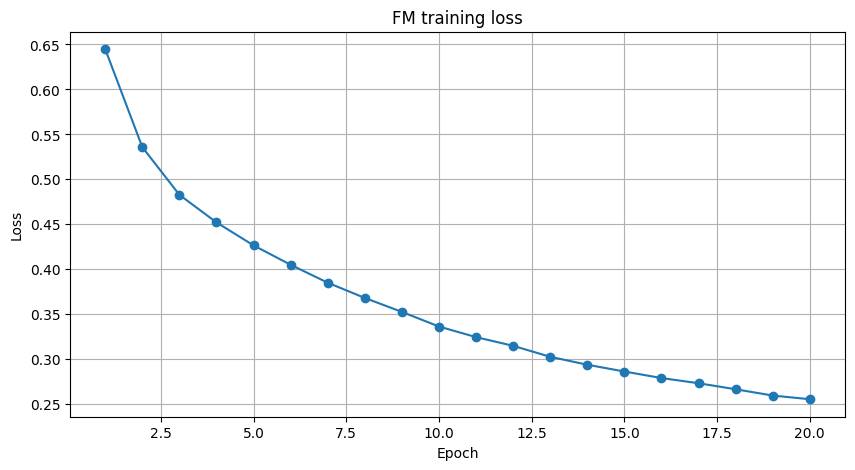

In [60]:
fm_history = pl.DataFrame(best_fm_model.history)
plt.figure(figsize=(10, 5))
plt.plot(fm_history["epoch"], fm_history["loss"], marker="o")
plt.title("FM training loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

Лучшая конфигурация достигается на 64 факторах (но не монотонно и рост факторов влиял на качество незначительно), learning_rate=0.001 и reg=1e-5: NDCG@10 = 0.0154, Recall@10 = 0.0308. Меньшая регуляризация стабильно давала лучший результат, а увеличение lr до 0.005 ухудшало качество. Лосс на трейне продолжает падать, поэтому имеет смысл запустить больше эпох.

In [65]:
FM_EXTRA_CONFIGS = [
    {
        **best_fm_parameters,
        "n_epochs": 40,
    }
]
(
    extra_fm_rows,
    extra_fm_model,
    extra_fm_parameters,
    extra_fm_details,
) = run_grid_search(FM, "FM", FM_EXTRA_CONFIGS, (train_matrix, fm_user_features, fm_item_features),
    validation_eval, train_matrix, train_user_to_index, train_item_to_index, k=K)
best_fm_score = max(row[PRIMARY_METRIC] for row in fm_rows)
extra_fm_score = extra_fm_rows[0][PRIMARY_METRIC]
if extra_fm_score > best_fm_score:
    best_fm_model = extra_fm_model
    best_fm_parameters = extra_fm_parameters
    best_fm_details = extra_fm_details
fm_rows.extend(extra_fm_rows)
validation_rows.extend(extra_fm_rows)
fm_validation = (
    pl.DataFrame(fm_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(fm_validation)
print(f"Лучшие параметры FM: {best_fm_parameters}")

FM 1/1: {'n_factors': 64, 'learning_rate': 0.001, 'reg': 1e-05, 'n_epochs': 40, 'batch_size': 2048, 'seed': 42}
  NDCG@10=0.0163, Recall@10=0.0336


model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""FM""","""{'n_factors': 64, 'learning_ra…",21.64,2.294,4798,0.01632,0.033556
"""FM""","""{'n_factors': 64, 'learning_ra…",26.588,2.312,4798,0.01632,0.033556
"""FM""","""{'n_factors': 64, 'learning_ra…",9.758,2.329,4798,0.015405,0.030846
"""FM""","""{'n_factors': 32, 'learning_ra…",9.147,1.73,4798,0.015306,0.031263
"""FM""","""{'n_factors': 32, 'learning_ra…",9.253,1.611,4798,0.015186,0.030221
"""FM""","""{'n_factors': 16, 'learning_ra…",9.455,1.47,4798,0.015113,0.030846
"""FM""","""{'n_factors': 64, 'learning_ra…",29.183,2.317,4798,0.015089,0.032722
"""FM""","""{'n_factors': 32, 'learning_ra…",9.296,1.664,4798,0.014108,0.02897
"""FM""","""{'n_factors': 16, 'learning_ra…",9.591,1.468,4798,0.013929,0.028554


Лучшие параметры FM: {'n_factors': 64, 'learning_rate': 0.001, 'reg': 1e-05, 'n_epochs': 40, 'batch_size': 2048, 'seed': 42}


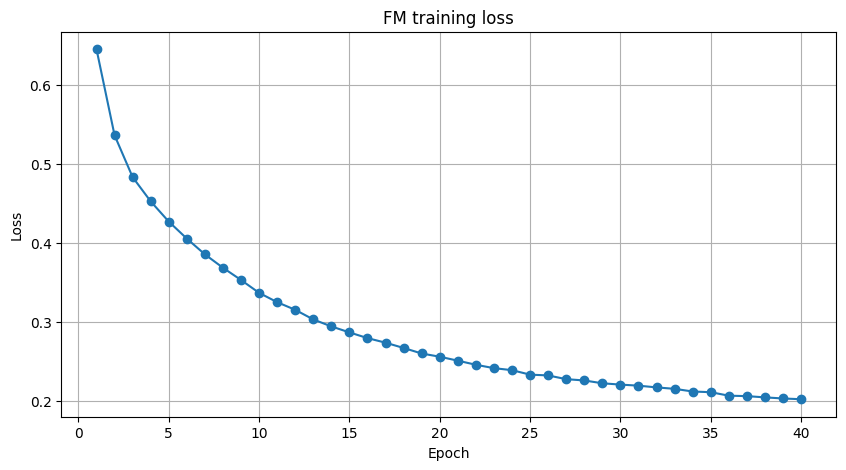

In [66]:
fm_history = pl.DataFrame(best_fm_model.history)
plt.figure(figsize=(10, 5))
plt.plot(fm_history["epoch"], fm_history["loss"], marker="o")
plt.title("FM training loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.grid(True)
plt.show()

In [67]:
FM_EXTRA_CONFIGS = [
    {
        **best_fm_parameters,
        "n_epochs": 60,
    }
]
(
    extra_fm_rows,
    extra_fm_model,
    extra_fm_parameters,
    extra_fm_details,
) = run_grid_search(FM, "FM", FM_EXTRA_CONFIGS, (train_matrix, fm_user_features, fm_item_features),
    validation_eval, train_matrix, train_user_to_index, train_item_to_index, k=K)
best_fm_score = max(row[PRIMARY_METRIC] for row in fm_rows)
extra_fm_score = extra_fm_rows[0][PRIMARY_METRIC]
if extra_fm_score > best_fm_score:
    best_fm_model = extra_fm_model
    best_fm_parameters = extra_fm_parameters
    best_fm_details = extra_fm_details
fm_rows.extend(extra_fm_rows)
validation_rows.extend(extra_fm_rows)
fm_validation = (
    pl.DataFrame(fm_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(fm_validation)
print(f"Лучшие параметры FM: {best_fm_parameters}")

FM 1/1: {'n_factors': 64, 'learning_rate': 0.001, 'reg': 1e-05, 'n_epochs': 60, 'batch_size': 2048, 'seed': 42}
  NDCG@10=0.0151, Recall@10=0.0327


model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""FM""","""{'n_factors': 64, 'learning_ra…",21.64,2.294,4798,0.01632,0.033556
"""FM""","""{'n_factors': 64, 'learning_ra…",26.588,2.312,4798,0.01632,0.033556
"""FM""","""{'n_factors': 64, 'learning_ra…",9.758,2.329,4798,0.015405,0.030846
"""FM""","""{'n_factors': 32, 'learning_ra…",9.147,1.73,4798,0.015306,0.031263
"""FM""","""{'n_factors': 32, 'learning_ra…",9.253,1.611,4798,0.015186,0.030221
"""FM""","""{'n_factors': 16, 'learning_ra…",9.455,1.47,4798,0.015113,0.030846
"""FM""","""{'n_factors': 64, 'learning_ra…",29.183,2.317,4798,0.015089,0.032722
"""FM""","""{'n_factors': 64, 'learning_ra…",28.523,2.33,4798,0.015089,0.032722
"""FM""","""{'n_factors': 32, 'learning_ra…",9.296,1.664,4798,0.014108,0.02897


Лучшие параметры FM: {'n_factors': 64, 'learning_rate': 0.001, 'reg': 1e-05, 'n_epochs': 40, 'batch_size': 2048, 'seed': 42}


Дальнейшие повышения количества эпох прироста метрик не дают, лосс выходит на плато.

## TimeSVD++

Обучаемся только на трейн-прочтениях с доступным рейтингом, а implicit-история включает все трейн-чтения: сначала для пользователя $u$ определяется его средний момент выставления оценки $\bar t_u$. Временное отклонение имеет вид
$$
dev_u(t)
=
\operatorname{sign}(t-\bar t_u)
|t-\bar t_u|^{0.4}.
$$

Implicit-компонента SVD++ строится по истории пользователя:
$$
h_u
=
\frac{1}{\sqrt{|N(u)|}}
\sum_{j\in N(u)}y_j,
$$
где N(u) - множество книг из доступной на момент обучения implicit-истории пользователя (трейн-чтения).

Эффективный пользовательский эмбеддинг в момент $t$:
$$
p_u(t)
=
p_u
+
\alpha_u^{(p)}dev_u(t)
+
h_u.
$$

Предсказанный рейтинг имеет вид
$$
\hat r_{ui}(t)
=
\mu
+
b_u
+
\alpha_u^{(b)}dev_u(t)
+
b_i
+
b_{i,\operatorname{bin}(t)}
+
q_i^\top p_u(t).
$$

Здесь:
- $\mu$ - средний рейтинг в трейне;
- $b_u$ и $b_i$ - базовые юзер/айтем смещения;
- $\alpha_u^{(b)}$ - временной дрифт смещения пользователя;
- $b_{i,\operatorname{bin}(t)}$ - смещение айтема для временного bin;
- $p_u$ и $q_i$ - латентные факторы пользователя и объекта;
- $\alpha_u^{(p)}$ - временной дрифт латентных предпочтений;
- $h_u$ - implicit-history компонента.

Параметры обучаются минимизацией MSE по наблюдаемым рейтингам с $L_2$-регуляризацией:
$$
\mathcal L
=
\frac{1}{|\mathcal D|}
\sum_{(u,i,t)\in\mathcal D}
\left(
r_{ui}-\hat r_{ui}(t)
\right)^2
+
\lambda\Omega.
$$

Несмотря на обучение по рейтингам, при оценке топ-10 значение $\hat r_{ui}(t)$ используется как скор для ранжирования, а релевантность остается общей для всех моделей: будущее read-взаимодействие.

В основной сетке проверяем влияние факторов и learning rate. Затем при фиксации лучших параметров отдельно выявляем влияние регуляризации, количества временных бакетов и эпох. Основной критерий выбора - NDCG@10; train RMSE показывает только сходимость обучения.

In [68]:
rated_train = train.filter(pl.col("rating").is_not_null())
tsvd_user_indices = np.fromiter(
    (train_user_to_index[int(value)] for value in rated_train["user_id"]),
    dtype=np.int64,
    count=rated_train.height,
)
tsvd_item_indices = np.fromiter(
    (train_item_to_index[int(value)] for value in rated_train["item_id"]),
    dtype=np.int64,
    count=rated_train.height,
)
tsvd_ratings = rated_train["rating"].to_numpy().astype(np.float32)
tsvd_timestamps = rated_train["event_ts"].to_numpy()
tsvd_user_histories = [
    train_matrix.getrow(user_index).indices.astype(np.int64, copy=True)
    for user_index in range(train_matrix.shape[0])
]
pl.DataFrame({
    "rated_interactions": [len(tsvd_ratings)],
    "rated_users": [np.unique(tsvd_user_indices).size],
    "all_users": [train_matrix.shape[0]],
    "rated_items": [np.unique(tsvd_item_indices).size],
    "all_items": [train_matrix.shape[1]],
    "rating_min": [float(tsvd_ratings.min())],
    "rating_max": [float(tsvd_ratings.max())],
})

rated_interactions,rated_users,all_users,rated_items,all_items,rating_min,rating_max
i64,i64,i64,i64,i64,f64,f64
83291,4547,4816,10215,10254,1.0,10.0


In [76]:
def evaluate_tsvdpp(
    model, evaluation, seen_matrix, user_to_index, item_to_index, k=10,
):
    rows = []
    for user_id, item_id, event_ts in evaluation.select(
        "user_id", "item_id", "event_ts",
    ).iter_rows():
        user_id, item_id = int(user_id), int(item_id)
        user_index = user_to_index[user_id]
        target_index = item_to_index[item_id]
        seen_indices = seen_matrix.getrow(user_index).indices
        scores = np.asarray(
            model.scores(user_index, np.datetime64(event_ts)),
            dtype=float,
        )
        recommended = models.utils.top_k_unseen(scores, seen_indices, k=k)
        matches = np.flatnonzero(recommended == target_index)
        rank = int(matches[0] + 1) if matches.size else None
        relevant = {target_index}
        rows.append({
            "user_id": user_id,
            "rank": rank,
            f"Recall@{k}": models.utils.recall_at_k(recommended, relevant, k=k),
            f"NDCG@{k}": models.utils.ndcg_at_k(recommended, relevant, k=k),
        })

    details = pl.DataFrame(rows, infer_schema_length=None)
    metrics = details.select(
        pl.len().alias("users"),
        pl.col(f"Recall@{k}").mean(),
        pl.col(f"NDCG@{k}").mean(),
    )
    return metrics, details

def run_tsvdpp_grid(configs):
    rows = []
    best_score = -np.inf
    for config_number, parameters in enumerate(configs, start=1):
        print(
            f"timeSVD++ {config_number}/{len(configs)}: "
            f"{parameters}"
        )
        model = TSVDPP(
            n_users=train_matrix.shape[0],
            n_items=train_matrix.shape[1],
            **parameters,
        )

        started = time.perf_counter()
        model.fit(
            tsvd_user_indices,
            tsvd_item_indices,
            tsvd_ratings,
            tsvd_timestamps,
            tsvd_user_histories,
        )
        fit_seconds = time.perf_counter() - started

        started = time.perf_counter()
        metrics, details = evaluate_tsvdpp(
            model, validation_eval, train_matrix,
            train_user_to_index, train_item_to_index, k=K,
        )
        eval_seconds = time.perf_counter() - started

        row = {
            "model": "timeSVD++",
            "parameters": str(parameters),
            "fit_sec": round(fit_seconds, 3),
            "eval_sec": round(eval_seconds, 3),
            **metrics.row(0, named=True),
        }
        rows.append(row)
        if row[PRIMARY_METRIC] > best_score:
            best_score = row[PRIMARY_METRIC]
            best_model = model
            best_parameters = parameters.copy()
            best_details = details
        print(
            f"  {PRIMARY_METRIC}={row[PRIMARY_METRIC]:.4f}, "
            f"{SECONDARY_METRIC}={row[SECONDARY_METRIC]:.4f}"
        )
    return rows, best_model, best_parameters, best_details

In [83]:
TSVDPP_CONFIGS = [
    {
        "n_factors": n_factors,
        "learning_rate": learning_rate,
        "reg": 2e-2,
        "n_epochs": 50,
        "n_time_bins": 8,
        "seed": SEED,
    }
    for n_factors in [16, 32, 64, 128, 256]
    for learning_rate in [1e-3, 5e-3]
]
validation_rows = [row for row in validation_rows if row["model"] != "timeSVD++"]
(
    tsvdpp_rows,
    best_tsvdpp_model,
    best_tsvdpp_parameters,
    best_tsvdpp_details,
) = run_tsvdpp_grid(TSVDPP_CONFIGS)
validation_rows.extend(tsvdpp_rows)
best_tsvdpp_score = max(row[PRIMARY_METRIC] for row in tsvdpp_rows)
tsvdpp_validation = (
    pl.DataFrame(tsvdpp_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(tsvdpp_validation)
print(f"Лучшие основные параметры timeSVD++: {best_tsvdpp_parameters}")

timeSVD++ 1/10: {'n_factors': 16, 'learning_rate': 0.001, 'reg': 0.02, 'n_epochs': 50, 'n_time_bins': 8, 'seed': 42}
  NDCG@10=0.0029, Recall@10=0.0054
timeSVD++ 2/10: {'n_factors': 16, 'learning_rate': 0.005, 'reg': 0.02, 'n_epochs': 50, 'n_time_bins': 8, 'seed': 42}
  NDCG@10=0.0008, Recall@10=0.0017
timeSVD++ 3/10: {'n_factors': 32, 'learning_rate': 0.001, 'reg': 0.02, 'n_epochs': 50, 'n_time_bins': 8, 'seed': 42}
  NDCG@10=0.0038, Recall@10=0.0075
timeSVD++ 4/10: {'n_factors': 32, 'learning_rate': 0.005, 'reg': 0.02, 'n_epochs': 50, 'n_time_bins': 8, 'seed': 42}
  NDCG@10=0.0016, Recall@10=0.0033
timeSVD++ 5/10: {'n_factors': 64, 'learning_rate': 0.001, 'reg': 0.02, 'n_epochs': 50, 'n_time_bins': 8, 'seed': 42}
  NDCG@10=0.0068, Recall@10=0.0113
timeSVD++ 6/10: {'n_factors': 64, 'learning_rate': 0.005, 'reg': 0.02, 'n_epochs': 50, 'n_time_bins': 8, 'seed': 42}
  NDCG@10=0.0019, Recall@10=0.0040
timeSVD++ 7/10: {'n_factors': 128, 'learning_rate': 0.001, 'reg': 0.02, 'n_epochs': 50, 

model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""timeSVD++""","""{'n_factors': 128, 'learning_r…",1.215,28.476,4798,0.011159,0.018341
"""timeSVD++""","""{'n_factors': 256, 'learning_r…",1.894,24.721,4798,0.007224,0.012297
"""timeSVD++""","""{'n_factors': 64, 'learning_ra…",0.74,14.624,4798,0.006841,0.011255
"""timeSVD++""","""{'n_factors': 128, 'learning_r…",1.215,13.468,4798,0.004958,0.008962
"""timeSVD++""","""{'n_factors': 256, 'learning_r…",1.912,25.302,4798,0.00459,0.008128
"""timeSVD++""","""{'n_factors': 32, 'learning_ra…",0.507,6.459,4798,0.003817,0.007503
"""timeSVD++""","""{'n_factors': 16, 'learning_ra…",1.064,5.381,4798,0.002923,0.005419
"""timeSVD++""","""{'n_factors': 64, 'learning_ra…",0.755,14.9,4798,0.001874,0.00396
"""timeSVD++""","""{'n_factors': 32, 'learning_ra…",0.522,4.472,4798,0.001563,0.003335


Лучшие основные параметры timeSVD++: {'n_factors': 128, 'learning_rate': 0.001, 'reg': 0.02, 'n_epochs': 50, 'n_time_bins': 8, 'seed': 42}


In [84]:
TSVDPP_REFINEMENT_CONFIGS = (
    [
        {
            **best_tsvdpp_parameters,
            "reg": 1e-3,
        }
    ]
    + [
        {
            **best_tsvdpp_parameters,
            "n_time_bins": n_time_bins,
        }
        for n_time_bins in [4, 12]
    ]
    + [
        {
            **best_tsvdpp_parameters,
            "n_epochs": n_epochs,
        }
        for n_epochs in [100, 200]
    ]
)
(
    ref_rows,
    ref_model,
    ref_parameters,
    ref_details,
) = run_tsvdpp_grid(TSVDPP_REFINEMENT_CONFIGS)
ref_score = max(row[PRIMARY_METRIC] for row in ref_rows)
if ref_score > best_tsvdpp_score:
    best_tsvdpp_score = ref_score
    best_tsvdpp_model = ref_model
    best_tsvdpp_parameters = ref_parameters
    best_tsvdpp_details = ref_details
tsvdpp_rows.extend(ref_rows)
validation_rows.extend(ref_rows)
tsvdpp_validation = (
    pl.DataFrame(tsvdpp_rows)
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(tsvdpp_validation)
print(f"Лучшие параметры timeSVD++: {best_tsvdpp_parameters}")

timeSVD++ 1/5: {'n_factors': 128, 'learning_rate': 0.001, 'reg': 0.001, 'n_epochs': 50, 'n_time_bins': 8, 'seed': 42}
  NDCG@10=0.0112, Recall@10=0.0183
timeSVD++ 2/5: {'n_factors': 128, 'learning_rate': 0.001, 'reg': 0.02, 'n_epochs': 50, 'n_time_bins': 4, 'seed': 42}
  NDCG@10=0.0113, Recall@10=0.0185
timeSVD++ 3/5: {'n_factors': 128, 'learning_rate': 0.001, 'reg': 0.02, 'n_epochs': 50, 'n_time_bins': 12, 'seed': 42}
  NDCG@10=0.0113, Recall@10=0.0183
timeSVD++ 4/5: {'n_factors': 128, 'learning_rate': 0.001, 'reg': 0.02, 'n_epochs': 100, 'n_time_bins': 8, 'seed': 42}
  NDCG@10=0.0072, Recall@10=0.0121
timeSVD++ 5/5: {'n_factors': 128, 'learning_rate': 0.001, 'reg': 0.02, 'n_epochs': 200, 'n_time_bins': 8, 'seed': 42}
  NDCG@10=0.0074, Recall@10=0.0127


model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""timeSVD++""","""{'n_factors': 128, 'learning_r…",1.25,11.243,4798,0.01133,0.018549
"""timeSVD++""","""{'n_factors': 128, 'learning_r…",1.092,11.365,4798,0.011293,0.018341
"""timeSVD++""","""{'n_factors': 128, 'learning_r…",1.083,18.23,4798,0.011186,0.018341
"""timeSVD++""","""{'n_factors': 128, 'learning_r…",1.215,28.476,4798,0.011159,0.018341
"""timeSVD++""","""{'n_factors': 128, 'learning_r…",4.061,18.595,4798,0.007411,0.012714
"""timeSVD++""","""{'n_factors': 256, 'learning_r…",1.894,24.721,4798,0.007224,0.012297
"""timeSVD++""","""{'n_factors': 128, 'learning_r…",2.064,11.271,4798,0.007205,0.012088
"""timeSVD++""","""{'n_factors': 64, 'learning_ra…",0.74,14.624,4798,0.006841,0.011255
"""timeSVD++""","""{'n_factors': 128, 'learning_r…",1.215,13.468,4798,0.004958,0.008962


Лучшие параметры timeSVD++: {'n_factors': 128, 'learning_rate': 0.001, 'reg': 0.02, 'n_epochs': 50, 'n_time_bins': 4, 'seed': 42}


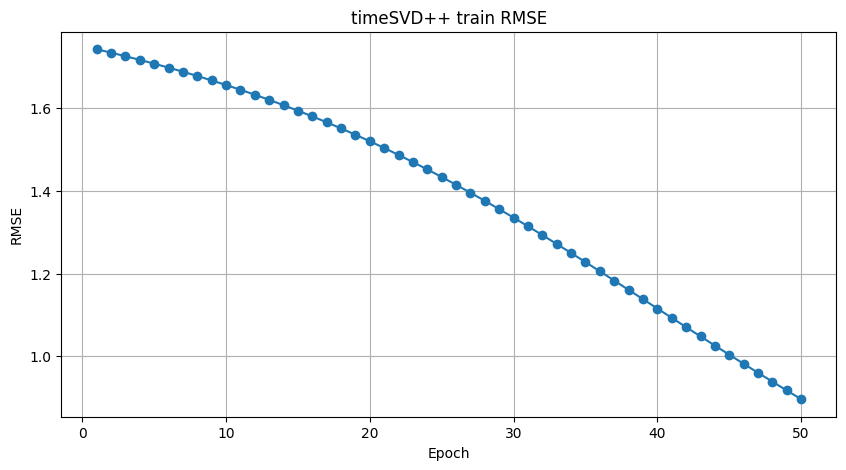

In [85]:
tsvdpp_history = pl.DataFrame(best_tsvdpp_model.history)
plt.figure(figsize=(10, 5))
plt.plot(
    tsvdpp_history["epoch"],
    tsvdpp_history["train_rmse"],
    marker="o",
)
plt.title("timeSVD++ train RMSE")
plt.xlabel("Epoch")
plt.ylabel("RMSE")
plt.grid(True)
plt.show()

Рост размерности до 128 факторов улучшает качество, но 256 факторов уже его ухудшили, в то время как регуляризация и число временных бакетов влияли слабо, а 100–200 эпох существенно ухудшали метрики. Это указывает на переобучение под регрессию по рейтингу и расхождение этой цели с ранжированием будущих прочтений.

In [86]:
best_validation = (
    pl.DataFrame(validation_rows)
    .sort(PRIMARY_METRIC, descending=True)
    .group_by("model", maintain_order=True)
    .first()
    .select(RESULT_COLS)
    .sort(PRIMARY_METRIC, descending=True)
)
display(best_validation)

model,parameters,fit_sec,eval_sec,users,NDCG@10,Recall@10
str,str,f64,f64,i64,f64,f64
"""EASE""","""{'reg': 10.0}""",2.663,25.438,4798,0.095868,0.142143
"""iALS""","""{'n_factors': 256, 'reg': 0.01…",900.597,6.584,4798,0.076424,0.121092
"""CF""","""{'n_neighbors': 50, 'shrinkage…",1.27,3.034,4798,0.070261,0.101084
"""FM""","""{'n_factors': 64, 'learning_ra…",21.64,2.294,4798,0.01632,0.033556
"""Popularity""","""-""",0.001,0.989,4798,0.011615,0.023343
"""timeSVD++""","""{'n_factors': 128, 'learning_r…",1.25,11.243,4798,0.01133,0.018549


Лучшей моделью стала EASE: NDCG@10 = 0.0959, Recall@10 = 0.1421. Она опередила iALS (0.0764 / 0.1211) и CF (0.0703 / 0.1011), при этом iALS потребовала существенно больше времени на обучение. CF показала наиболее выгодный компромисс между качеством и скоростью среди коллаборативных моделей. FM лишь умеренно превзошла Popularity (0.0163 против 0.0116 по NDCG@10), а timeSVD++ немного ей уступила (0.0113), что согласуется с несовпадением регрессии по рейтингу и целевой задачи ранжирования. Прирост EASE относительно Popularity составил 0.0843 NDCG@10. Далее фиксируем выбранные параметры, выполняем рефит на трейне+вале и оцениваем все модели на тесте.